# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 : Cicoria, Ignacio
- Alumno 2 : Ricci, Guillermo

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [1]:

# URL del fork
REPO_URL = "https://github.com/guillericci/tuia-dog-recognition-app.git"

# Clonar la rama
!git clone --branch feature/tp2-razas-perros $REPO_URL proyecto

# Entrar al repositorio
%cd proyecto


Cloning into 'proyecto'...
remote: Enumerating objects: 214, done.
remote: Counting objects: 100% (105/105), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 214 (delta 80), reused 67 (delta 66), pack-reused 109 (from 1)
Receiving objects: 100% (214/214), 1019.01 KiB | 44.30 MiB/s, done.
Resolving deltas: 100% (122/122), done.
/content/proyecto


In [2]:
# %cd /content/proyecto
# !git pull origin feature/tp2-razas-perros
# !git log -1 --stat | head -20
# !ls src/lib/models

[Errno 2] No such file or directory: '/content/proyecto'
/content
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
ls: cannot access 'src/lib/models': No such file or directory


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [50]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime ultralytics

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [49]:
import os
import sys
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import shutil, json
import pandas as pd
from pathlib import Path
import json
from tqdm.auto import tqdm


os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings
from lib.bootstrap import build_detection
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.

In [4]:
!python scripts/download_dataset.py

## TO-DO: cargar los splits guardados en 1-pre-processing.ipynb y el conjunto independiente.

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Dataset disponible en /content/proyecto/data/dataset


In [5]:

from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/TUIA/COMPUTER VISION/DOG RECOGNITION/Datasets")
shutil.copytree(BASE / "splits", settings.data_path / "splits", dirs_exist_ok=True)
shutil.copytree(BASE / "independent_dataset", settings.dataset_path / "independent", dirs_exist_ok=True)

# Verificación: los CSV apuntan a archivos que existen y las razas son las esperadas
S = settings.data_path / "splits"
meta = json.loads((S / "meta.json").read_text(encoding="utf-8"))
for s in ["train", "valid", "test"]:
    d = pd.read_csv(S / f"{s}.csv")
    faltan = [p for p in d.path if not (settings.data_path / p).exists()]
    print(f"{s}: {len(d)} imágenes | razas: {d.breed.nunique()} | rutas inexistentes: {len(faltan)}")
print("clases en meta.json:", len(meta["classes"]), "| semilla:", meta["seed"])

Mounted at /content/drive
train: 7686 imágenes | razas: 70 | rutas inexistentes: 0
valid: 690 imágenes | razas: 70 | rutas inexistentes: 0
test: 700 imágenes | razas: 70 | rutas inexistentes: 0
clases en meta.json: 70 | semilla: 42


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

TO-DO:
- Galería: imágenes de `train`. Consultas: `test` y el conjunto independiente (nunca indexadas).
- Para cada consulta, recuperar las Top-10 y calcular NDCG@10 con relevancia binaria (misma raza).
- Reportar NDCG@10 medio, precision@10 y accuracy de la raza predicha, por separado para `test` y
  para el conjunto independiente.
- Comparar `cosine` vs `l2`, analizar `TOP_K` y calibrar `SIMILARITY_THRESHOLD` con validación.
- Justificar el resultado con ejemplos de consultas y sus Top-10.

Sugerencia: no hace falta la base de datos. Calculá los embeddings de la galería en una matriz de
`numpy` y buscá con un producto matricial (`EmbeddingStore.append` reescribe el JSON en cada llamada).

In [10]:

CLASSES = json.loads((S / "meta.json").read_text(encoding="utf-8"))["classes"]
CI = {c: i for i, c in enumerate(CLASSES)}

def cargar_split(nombre):
    d = pd.read_csv(S / f"{nombre}.csv")
    return [settings.data_path / p for p in d.path], d.breed.map(CI).to_numpy()

train_p, gy = cargar_split("train")
valid_p, vy = cargar_split("valid")
test_p, ty = cargar_split("test")

INDEP = settings.dataset_path / "independent"
f = INDEP / "metadata_candidates.csv"
try:
    meta = pd.read_csv(f, encoding="utf-8-sig")
except UnicodeDecodeError:
    meta = pd.read_csv(f, encoding="cp1252")
ind, none = meta[meta.type == "single"].reset_index(drop=True), meta[meta.type == "none"].reset_index(drop=True)
assert ind.breed.isin(CI).all(), "Hay razas del independiente que no están en CLASSES"
indep_p, iy = [INDEP / p for p in ind.path], ind.breed.map(CI).to_numpy()
none_p = [INDEP / p for p in none.path]

print(f"train {len(train_p)} | valid {len(valid_p)} | test {len(test_p)} | independiente {len(indep_p)} "
      f"({ind.breed.nunique()} razas) | sin perros {len(none_p)}")

train 7686 | valid 690 | test 700 | independiente 110 (22 razas) | sin perros 9


In [11]:
similarity = build_similarity(settings, build_store(settings))
EMB_DIR = settings.output_path / "embeddings"; EMB_DIR.mkdir(parents=True, exist_ok=True)

def embeddings_baseline(nombre, paths):
    cache = EMB_DIR / f"baseline__{nombre}.npy"
    if cache.exists():
        E = np.load(cache)
        assert len(E) == len(paths), f"Caché desactualizado: borrá {cache}"
        return E
    E = np.array([similarity.extract_embedding(cv2.imread(str(p))) for p in tqdm(paths, desc=nombre)], dtype=np.float32)
    np.save(cache, E)
    return E

G  = embeddings_baseline("train", train_p)      # galería
Qv = embeddings_baseline("valid", valid_p)      # solo para calibrar el umbral
Qt = embeddings_baseline("test", test_p)
Qi = embeddings_baseline("indep", indep_p)
Qn = embeddings_baseline("none", none_p)        # imágenes sin perros (control del umbral)

print("galería:", G.shape, "| dim esperada:", settings.embedding_dim)
assert G.shape[1] == settings.embedding_dim
assert np.allclose(np.linalg.norm(G, axis=1), 1, atol=1e-3), "Los embeddings no están normalizados L2"

galería: (7686, 512) | dim esperada: 512


NDCG@10, precision@10 y accuracy de raza, cosine vs l2

In [12]:
def similitud(Q, G_, metrica):
    if metrica == "cosine":
        return Q @ G_.T                                   # vectores normalizados: producto punto = coseno
    d2 = (Q ** 2).sum(1)[:, None] + (G_ ** 2).sum(1)[None, :] - 2 * Q @ G_.T
    return 1.0 / (1.0 + np.sqrt(np.maximum(d2, 0)))       # igual que SimilarityService._l2_similarity

def predecir(S, top):
    """Raza predicha con la función REAL del servicio (voto ponderado), sin umbral. Devuelve (razas, mejor score)."""
    umbral, similarity.similarity_threshold = similarity.similarity_threshold, float("-inf")
    try:
        pred = [similarity.predict_breed_from_neighbors(
                    [Neighbor(path="", breed=CLASSES[gy[j]], score=float(S[i, j])) for j in top[i]])[0]
                for i in range(len(S))]
    finally:
        similarity.similarity_threshold = umbral
    return np.array(pred), S.max(1)

def evaluar(Q, qy, G_, metrica="cosine", k=10):
    S = similitud(Q, G_, metrica)
    top = np.argsort(-S, axis=1)[:, :k]
    rel = (gy[top] == qy[:, None]).astype(float)                       # relevancia binaria: misma raza
    n_rel = np.bincount(gy, minlength=len(CLASSES))[qy]                # imágenes de esa raza en la galería
    ndcg = np.mean([ndcg_at_k(rel[i], k, int(n_rel[i])) for i in range(len(qy))])
    pred, _ = predecir(S, top)
    return {"NDCG@k": ndcg, "P@k": rel.mean(), "acc_raza": (pred == np.array(CLASSES)[qy]).mean()}

consultas = {"test": (Qt, ty), "independiente": (Qi, iy)}
tabla_e1 = pd.DataFrame([{"consultas": c, "métrica": m, **{n: round(float(v), 4) for n, v in evaluar(Q, qy, G, m).items()}}
                         for c, (Q, qy) in consultas.items() for m in ["cosine", "l2"]])
tabla_e1

,consultas,métrica,NDCG@k,P@k,acc_raza
0,test,cosine,0.8735,0.8597,0.9329
1,test,l2,0.8735,0.8597,0.9329
2,independiente,cosine,0.6203,0.6045,0.7000
3,independiente,l2,0.6203,0.6045,0.7000


**cosine y l2.** Los resultados son idénticos. Con embeddings normalizados L2: la distancia
euclídea es una función decreciente del coseno, así que ambas métricas ordenan igual a los vecinos y solo cambia la
escala del score (y, por lo tanto, el valor del umbral).


**Cambio de dominio.** El NDCG@10 baja de 0.874 (test) a 0.620 (independiente), y la accuracy de raza de 0.933 a 0.700.


In [13]:
ks = [1, 3, 5, 10, 20, 50]
pd.DataFrame([{"consultas": c, "k": k, **{n: round(float(v), 4) for n, v in evaluar(Q, qy, G, "cosine", k).items()}}
              for c, (Q, qy) in consultas.items() for k in ks])

,consultas,k,NDCG@k,P@k,acc_raza
0,test,1,0.9286,0.9286,0.9286
1,test,3,0.9062,0.8995,0.9343
2,test,5,0.8948,0.8857,0.9414
3,test,10,0.8735,0.8597,0.9329
4,test,20,0.8460,0.8275,0.9329
5,test,50,0.7860,0.7578,0.9200
6,independiente,1,0.6909,0.6909,0.6909
7,independiente,3,0.6598,0.6515,0.6909
8,independiente,5,0.6395,0.6255,0.6818
9,independiente,10,0.6203,0.6045,0.7000



- **TOP_K:** la accuracy se mantiene prácticamente igual para valores entre 3 y 20. Con k=50 disminuye un poco. Al aumentar k, también se incorporan vecinos de otras razas, por eso bajan Precision@k y NDCG@k. Se mantiene k=10, como establece el enunciado.

### Calibrar `SIMILARITY_THRESHOLD` con validación

In [14]:
def calibrar(G_, Qv_, Qn_, objetivo_acc=0.95, cobertura_min=0.80, k=10):
    """Umbral para 'unknown'. Se calibra con valid (consultas reales); las imágenes sin perros son solo un control."""
    Sv = Qv_ @ G_.T
    top = np.argsort(-Sv, axis=1)[:, :k]
    pred, best = predecir(Sv, top)
    ok = pred == np.array(CLASSES)[vy]
    best_n = (Qn_ @ G_.T).max(1)
    ts = np.unique(np.quantile(best, np.linspace(0, 0.6, 13)).round(3))
    tabla = pd.DataFrame({"umbral": ts,
                          "cobertura (aceptadas)": [(best >= t).mean() for t in ts],
                          "acc de las aceptadas": [ok[best >= t].mean() for t in ts],
                          "sin perros rechazadas": [(best_n < t).mean() for t in ts]}).round(3)
    cand = np.linspace(best.min(), best.max(), 400)
    validos = [t for t in cand if (best >= t).mean() >= cobertura_min and ok[best >= t].mean() >= objetivo_acc]
    return tabla, (float(min(validos)) if validos else None)

tabla_u, t_sug = calibrar(G, Qv, Qn)
display(tabla_u)
print("Umbral sugerido (coseno):", None if t_sug is None else round(t_sug, 3))

UMBRAL = t_sug            # <- decisión tuya: podés fijar otro valor a mano mirando la tabla
if UMBRAL is not None:
    print("Equivalente en l2:", round(1 / (1 + np.sqrt(2 - 2 * UMBRAL)), 3))
    for c, (Q, qy) in consultas.items():
        S = Q @ G.T; top = np.argsort(-S, axis=1)[:, :10]
        pred, best = predecir(S, top); acept = best >= UMBRAL
        print(f"{c:14s} cobertura {acept.mean():.3f} | acc de las aceptadas {(pred == np.array(CLASSES)[qy])[acept].mean():.3f}"
              f" | acc sin umbral {(pred == np.array(CLASSES)[qy]).mean():.3f}")
    print(f"Sin perros rechazadas con ese umbral: {(Qn @ G.T).max(1).__lt__(UMBRAL).mean():.2f} (de {len(Qn)} imágenes)")

,umbral,cobertura (aceptadas),acc de las aceptadas,sin perros rechazadas
0,0.803,0.999,0.936,0.889
1,0.848,0.946,0.940,1.000
2,0.859,0.901,0.944,1.000
3,0.870,0.849,0.947,1.000
4,0.875,0.803,0.951,1.000
5,0.880,0.745,0.953,1.000
6,0.884,0.690,0.950,1.000
7,0.888,0.649,0.951,1.000
8,0.892,0.600,0.952,1.000
9,0.896,0.546,0.950,1.000


Umbral sugerido (coseno): 0.874
Equivalente en l2: 0.665
test           cobertura 0.806 | acc de las aceptadas 0.940 | acc sin umbral 0.933
independiente  cobertura 0.282 | acc de las aceptadas 0.935 | acc sin umbral 0.700
Sin perros rechazadas con ese umbral: 1.00 (de 9 imágenes)




- **Umbral:** el valor original (0.55) no rechaza ninguna consulta, porque todos los scores de validación son superiores. Se eligió un umbral más alto (≈0.85), que rechaza las 9 imágenes sin perros y conserva aproximadamente el 95 % de las consultas legítimas de validación. Esto permite descartar imágenes que no pertenecen al dominio esperado, aunque no soluciona las confusiones entre razas visualmente similares.

- **Limitación:** este umbral fue ajustado para el modelo baseline. Si se utilizan otros embeddings, será necesario volver a calibrarlo, porque los valores de similitud pueden cambiar.

== test: top-1 correcto en 0.929 de las consultas ==


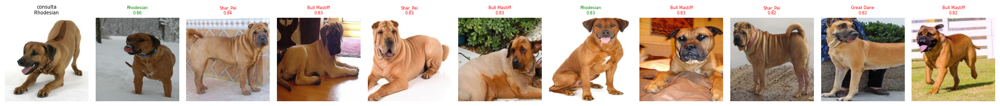

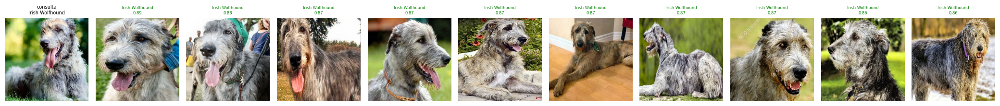

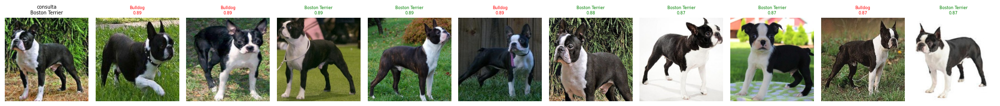

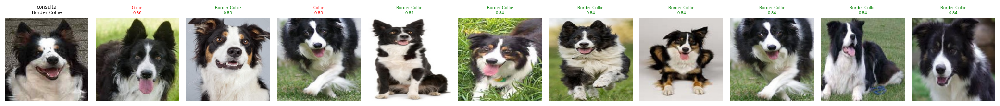

== independiente: top-1 correcto en 0.691 de las consultas ==


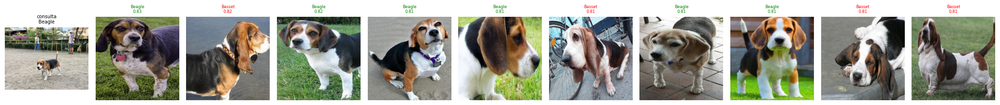

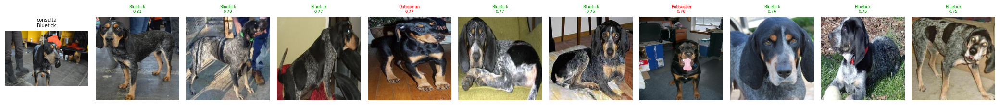

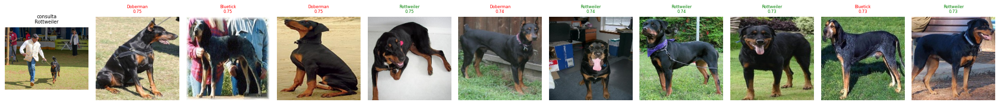

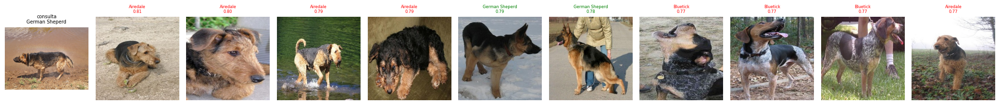

In [15]:
def rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)

def mostrar_consulta(Q, qy, qpaths, i, k=10):
    s = Q[i] @ G.T
    top = np.argsort(-s)[:k]
    fig, axes = plt.subplots(1, k + 1, figsize=(1.9 * (k + 1), 2.6))
    for a in axes:
        a.axis("off")
    axes[0].imshow(rgb(qpaths[i])); axes[0].set_title(f"consulta\n{CLASSES[qy[i]]}", fontsize=7)
    for a, j in zip(axes[1:], top):
        a.imshow(rgb(train_p[j]))
        a.set_title(f"{CLASSES[gy[j]]}\n{s[j]:.2f}", fontsize=6, color="green" if gy[j] == qy[i] else "red")
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
for nombre, (Q, qy, qp) in {"test": (Qt, ty, test_p), "independiente": (Qi, iy, indep_p)}.items():
    top1 = gy[(Q @ G.T).argmax(1)] == qy
    bien, mal = np.flatnonzero(top1), np.flatnonzero(~top1)
    print(f"== {nombre}: top-1 correcto en {top1.mean():.3f} de las consultas ==")
    for i in list(rng.choice(bien, 2, replace=False)) + list(rng.choice(mal, min(2, len(mal)), replace=False)):
        mostrar_consulta(Q, qy, qp, i)

## 6. Modelo A: fine-tuning de ResNet

`train_classifier` debe guardar el checkpoint en `models/resnet18_finetuned.pth`
(o el nombre configurado en `RESNET18_MODEL_NAME`). Documentar la estrategia de fine-tuning
y los hiperparámetros utilizados (learning rate, batch size, epochs, optimizador, scheduler,
regularización).

**Arquitectura.** ResNet18 preentrenada en ImageNet (≈11 M de parámetros). Se quita su capa final de 1000 clases y se agrega Dropout(0.2) + Linear(512 → 70), una salida por raza. La salida de 512 valores previa a la cabeza es el embedding que se usa en la búsqueda por similitud.

**Preprocesamiento.** BGR→RGB, resize a 224×224 y normalización con media y desvío de ImageNet (`lib/preprocessing.py`), idéntico en entrenamiento y en la app. En train se agrega la augmentation antes de normalizar.

**Estrategias comparadas**:
1. *Fine-tuning completo* con learning rates diferenciados: 1e-3 en la cabeza (parte de cero) y 1e-4 en el backbone (ya preentrenado, un valor alto destruiría las features aprendidas).
2. *Feature extraction*: backbone congelado (con BatchNorm en modo eval), solo se entrena la cabeza.
3. *Fine-tuning completo con class weights* (peso inverso a la frecuencia de cada raza).

**Hiperparámetros comunes.** AdamW, weight decay 1e-4, dropout 0.2, label smoothing 0.1, scheduler cosine annealing, batch 64, hasta 15 épocas con early stopping (paciencia 4) sobre la accuracy de validación, precisión mixta (AMP), semilla 42. Se guarda el checkpoint del mejor epoch según validación.

**Por qué label smoothing.** Con razas parecidas entre sí, evita que el modelo se vuelva sobreconfiado. Por eso la loss de train se estanca cerca de 0.16 aunque la accuracy sea ~99 %: las curvas de la sección siguiente muestran la cross-entropy sin suavizado en train y validación.

In [40]:
from lib.bootstrap import build_classifier
classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_config = {"strategy": "finetune", "epochs": 15, "tag": "resnet18_finetuned"}
classifier.train_classifier()

In [8]:
# Modelo A: test
metrics_a = classifier.evaluate_classifier()
print({k: round(v, 4) for k, v in metrics_a.items()})

# Modelo A: conjunto independiente (solo imágenes de un perro)
INDEP = settings.dataset_path / "independent"
f = INDEP / "metadata.csv" if (INDEP / "metadata.csv").exists() else INDEP / "metadata_candidates.csv"
try:
    ind = pd.read_csv(f, encoding="utf-8-sig")
except UnicodeDecodeError:
    ind = pd.read_csv(f, encoding="cp1252")
ind = ind[ind.type == "single"]
metrics_a_ind = classifier.evaluate_paths([INDEP / p for p in ind.path], ind.breed.tolist(), name="independent")
print({k: round(v, 4) for k, v in metrics_a_ind.items()})

# Chequeo del embedding: 512 valores, norma 1
import cv2, numpy as np
emb = classifier.extract_custom_embedding(cv2.imread(str(INDEP / ind.path.iloc[0])))
print(len(emb), round(float(np.linalg.norm(emb)), 4))

{'accuracy': 0.9671, 'precision': 0.9688, 'recall': 0.9671, 'specificity': 0.9995, 'f1': 0.9665}
{'accuracy': 0.6364, 'precision': 0.8951, 'recall': 0.6364, 'specificity': 0.9965, 'f1': 0.7007}
512 1.0


### Curvas de entrenamiento y matriz de confusión (Modelo A)

TO-DO: graficar las curvas de entrenamiento/validación (loss y accuracy) y la matriz de confusión
normalizada, con los pares de razas más confundidos.

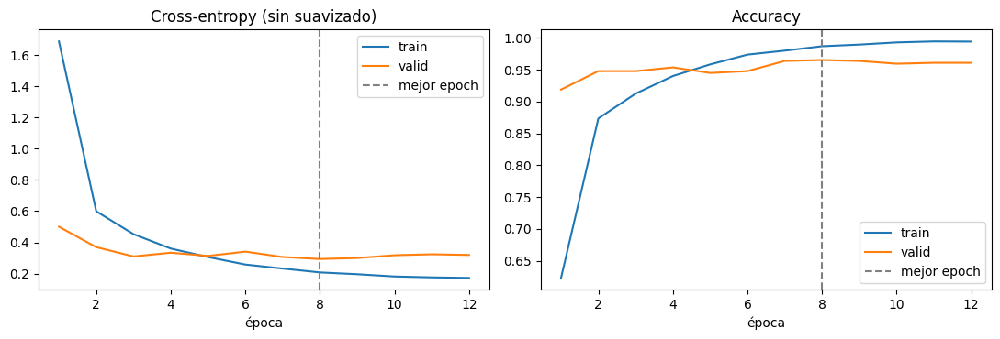

In [9]:
import numpy as np, matplotlib.pyplot as plt, cv2

# --- c) Curvas de entrenamiento ---
H = json.loads((settings.output_path / "history_resnet18_finetuned.json").read_text())
h = H["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, t in zip(ax, ["loss", "acc"], ["Cross-entropy (sin suavizado)", "Accuracy"]):
    a.plot(h["epoch"], h[f"train_{k}"], label="train"); a.plot(h["epoch"], h[f"val_{k}"], label="valid")
    a.axvline(H["best_epoch"], ls="--", c="gray", label="mejor epoch"); a.set_title(t); a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

### Matriz de confusion

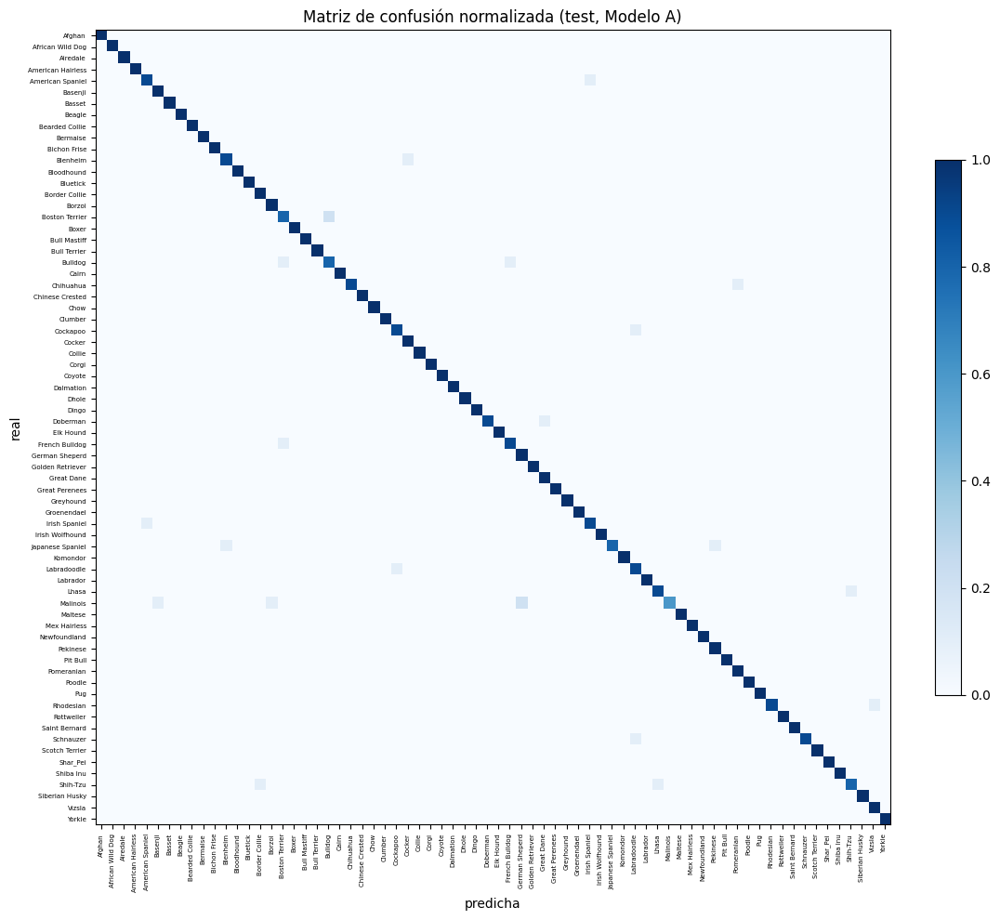

In [10]:
# --- a) y b) sobre test ---
classifier.set_active_model("resnet18_finetuned")
classifier.evaluate_classifier()
ev = classifier.last_eval["resnet18_finetuned:test"]
C, yt, yp, P = ev["classes"], ev["y_true"], ev["y_pred"], ev["probs"]
n = len(C)
cnt = np.bincount(yt * n + yp, minlength=n * n).reshape(n, n)
cmn = cnt / cnt.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(C, rotation=90, fontsize=5)
ax.set_yticks(range(n)); ax.set_yticklabels(C, fontsize=5)
ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title("Matriz de confusión normalizada (test, Modelo A)")
plt.colorbar(im, fraction=0.03); plt.tight_layout(); plt.show()


Pares más confundidos (real -> predicha):
            real       predicha  veces  de
        Malinois German Sheperd      2  10
  Boston Terrier        Bulldog      2  10
       Schnauzer    Labradoodle      1  10
        Shih-Tzu          Lhasa      1  10
       Rhodesian         Vizsla      1  10
           Lhasa       Shih-Tzu      1  10
        Malinois        Basenji      1  10
        Shih-Tzu  Border Collie      1  10
     Labradoodle       Cockapoo      1  10
Japanese Spaniel       Pekinese      1  10

Razas con peor F1:
            raza  precision  recall  soporte    f1
        Malinois      1.000     0.6       10 0.750
         Bulldog      0.800     0.8       10 0.800
  Boston Terrier      0.800     0.8       10 0.800
        Shih-Tzu      0.889     0.8       10 0.842
     Labradoodle      0.818     0.9       10 0.857
Japanese Spaniel      1.000     0.8       10 0.889
American Spaniel      0.900     0.9       10 0.900
        Cockapoo      0.900     0.9       10 0.900
  Fren

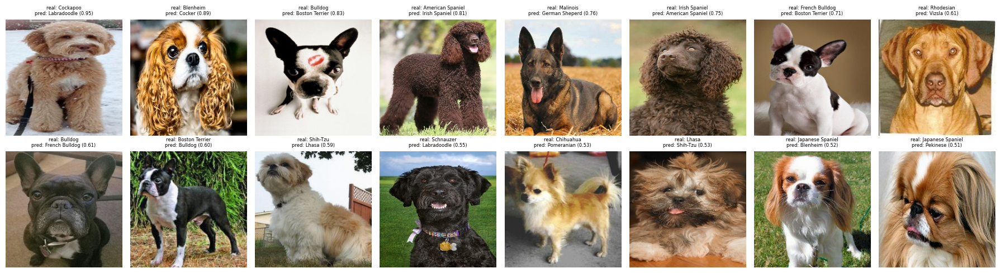

In [11]:
off = cnt.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:10], off.shape))[0]
print("Pares más confundidos (real -> predicha):")
print(pd.DataFrame([{"real": C[i], "predicha": C[j], "veces": int(off[i, j]), "de": int(cnt[i].sum())}
                    for i, j in top if off[i, j] > 0]).to_string(index=False))

tp = np.diag(cnt); sup = cnt.sum(1); pr = cnt.sum(0)
tabla = pd.DataFrame({"raza": C, "precision": tp / np.maximum(pr, 1), "recall": tp / sup, "soporte": sup})
tabla["f1"] = 2 * tabla.precision * tabla.recall / np.maximum(tabla.precision + tabla.recall, 1e-9)
print("\nRazas con peor F1:"); print(tabla.sort_values("f1").head(10).round(3).to_string(index=False))

# --- f) Errores con imagen y score ---
err = np.flatnonzero(yt != yp)
print(f"\nErrores en test: {len(err)} de {len(yt)}")
sel = err[np.argsort(-P[err, yp[err]])][:16]         # los errores donde el modelo estaba MÁS seguro
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax_, i in zip(axes.ravel(), sel):
    ax_.imshow(cv2.cvtColor(cv2.imread(ev["paths"][i]), cv2.COLOR_BGR2RGB)); ax_.axis("off")
    ax_.set_title(f"real: {C[yt[i]]}\npred: {C[yp[i]]} ({P[i, yp[i]]:.2f})", fontsize=6)
plt.tight_layout(); plt.show()

### Métricas

- **Accuracy:** fracción de imágenes bien clasificadas.
- **Precision (por clase):** de lo que el modelo etiquetó como esa raza, qué fracción lo era (TP/(TP+FP)).
- **Recall o sensibilidad (por clase):** de las imágenes de esa raza, qué fracción encontró (TP/(TP+FN)).
- **F1:** media armónica de precision y recall.
- **Especificidad (por clase):** de las imágenes que NO son esa raza, qué fracción descartó (TN/(TN+FP)).
- **Promedio macro:** precision, recall, F1 y especificidad se calculan por raza (one-vs-rest) y se promedian con el mismo peso para las 70 razas.

**Interpretacion.**
- En test hay exactamente 10 imágenes por raza, por lo que el recall macro coincide con la accuracy(por eso ambas valen 0.9629).
- La especificidad es ≈ 1 por construcción: con 70 clases, cada raza tiene unos 690 negativos, y aun con 3 falsos positivos sigue por encima de 0.995. No sirve para comparar modelos; la usamos solo porque el enunciado la pide.
- Con 700 imágenes, el intervalo de confianza aproximado de la accuracy es de ±1.4 puntos; con 110
  (conjunto independiente), de ±9 puntos. Diferencias menores a eso no son concluyentes.
- Una imagen mal clasificada baja 10 puntos el recall de su raza (10 imágenes por raza), por lo que
  las métricas por raza son poco estables.
- En el conjunto independiente solo hay 22 razas: el promedio macro se calcula sobre ellas. La
  precision resulta optimista, porque no cuenta los falsos positivos que caen en las otras 48 razas;
  por eso el titular de ese conjunto es accuracy/recall.

### Resultados del Modelo A en test

| accuracy | precision | recall | specificity | F1 |
|---|---|---|---|---|
| 0.9629 | 0.9652 | 0.9629 | 0.9995 | 0.9627 |

26 errores sobre 700 imágenes. Razas con peor F1: Bulldog y Boston Terrier (0.70), Malinois (0.71) y German Shepherd (0.78).

**Pares más confundidos:**
* Malinois → German Shepherd (3 de 10)
* Boston Terrier → Bulldog (3 de 10)
* Bulldog → Boston Terrier (2)
* Chinese Crested → Mex Hairless (2)
* American Spaniel → Irish Spaniel (2).


**Análisis de errores:** El modelo confunde las razas porque se comparten características visuales, tienen variaciones morfológicas dentro de una misma raza o aparecen en imágenes donde las características distintivas no son suficientemente visibles.
Por ejemplo:
* **Malinois ↔ German Shepherd:** Ambas razas tienen hocico alargado, orejas erectas, patrones de coloración marrón, negro, y algunas posturas hacen que sus siluetas sean muy parecidas.
* **Boston Terrier ↔ Bulldog:** Ambas razas tienen hocico corto, presentan cabeza ancha, ojos prominentes y cuerpo compacto. Pueden compartir patrones de pelaje blanco y oscuro
* **American Spaniel ↔ Irish Spaniel:** Ambas razas pertenecen al grupo de perros de tipo spaniel. Presentan pelajes largos, ondulados o rizados. Comparten características de orejas caídas y morfología general.

**Curvas de entrenamiento.** El mejor epoch fue el 10 y el early stopping cortó en el 14. La accuracy de train llega a 99.8 % y la de validación se estabiliza en ≈ 96–97 % desde la época 6; la loss de validación queda plana desde la época 6-7. La brecha de ~3 puntos indica sobreajuste leve, esperable con
7686 imágenes y 70 razas. No hay subajuste: la accuracy de train es alta.

### Comparacion de estrategias Resnet

In [12]:
experimentos = {
    "resnet18_headonly":        {"strategy": "head_only", "epochs": 15},
    "resnet18_ft_classweights": {"strategy": "finetune", "epochs": 15, "use_class_weights": True},
}
for tag, extra in experimentos.items():
    classifier.set_active_model("resnet18_finetuned")        # train_classifier solo acepta este nombre por ahora
    classifier.train_config = {**extra, "tag": tag, "save_as_active": False}
    classifier.train_classifier()

# Comparación por VALIDACIÓN (criterio de elección) y luego test (para reportar)
tags = ["resnet18_finetuned"] + list(experimentos)
filas = []
for tag in tags:
    H = json.loads((settings.output_path / f"history_{tag}.json").read_text())
    if tag != "resnet18_finetuned":
        classifier.checkpoints[tag] = settings.output_path / f"{tag}.pth"
    classifier.set_active_model(tag)
    m = classifier.evaluate_classifier()
    filas.append({"experimento": tag, "mejor_epoch": H["best_epoch"], "val_acc": round(H["best_val_acc"], 4),
                  **{f"test_{k}": round(v, 4) for k, v in m.items()}})
classifier.set_active_model("resnet18_finetuned")
pd.DataFrame(filas)

[resnet18_headonly] ep 01/15 | train loss 2.151 acc 0.546 | val loss 0.747 acc 0.891 | 28s
[resnet18_headonly] ep 02/15 | train loss 0.884 acc 0.819 | val loss 0.457 acc 0.929 | 56s
[resnet18_headonly] ep 03/15 | train loss 0.709 acc 0.848 | val loss 0.386 acc 0.932 | 83s
[resnet18_headonly] ep 04/15 | train loss 0.634 acc 0.861 | val loss 0.364 acc 0.935 | 110s
[resnet18_headonly] ep 05/15 | train loss 0.607 acc 0.871 | val loss 0.350 acc 0.941 | 139s
[resnet18_headonly] ep 06/15 | train loss 0.590 acc 0.877 | val loss 0.342 acc 0.932 | 167s
[resnet18_headonly] ep 07/15 | train loss 0.567 acc 0.880 | val loss 0.336 acc 0.941 | 200s
[resnet18_headonly] ep 08/15 | train loss 0.555 acc 0.885 | val loss 0.334 acc 0.938 | 228s
[resnet18_headonly] ep 09/15 | train loss 0.533 acc 0.895 | val loss 0.326 acc 0.938 | 255s
[resnet18_headonly] ep 10/15 | train loss 0.536 acc 0.891 | val loss 0.324 acc 0.941 | 283s
[resnet18_headonly] ep 11/15 | train loss 0.524 acc 0.896 | val loss 0.321 acc 0.93

,experimento,mejor_epoch,val_acc,test_accuracy,test_precision,test_recall,test_specificity,test_f1
0,resnet18_finetuned,8,0.9652,0.9671,0.9688,0.9671,0.9995,0.9665
1,resnet18_headonly,14,0.9435,0.9600,0.9621,0.9600,0.9994,0.9595
2,resnet18_ft_classweights,15,0.9667,0.9771,0.9782,0.9771,0.9997,0.9771


 **Comparación de configuraciones de ResNet18**

- **Fine-tuning vs. feature extraction:** el fine-tuning completo obtuvo mejores resultados en validación que `headonly` (96.52 % frente a 94.35 %). En test también obtuvo una accuracy ligeramente superior (96.71 % frente a 96 %).
- **Con y sin class weights:** ambas configuraciones tuvieron resultados similares en validación. En test, `classweights` obtuvo una accuracy mayor (97.71 % frente a 96.71 %).
- **Configuración elegida:** se seleccionó `resnet18_finetuned`, porque la elección se realizó utilizando validación y se priorizó una configuración más simple, sin agregar pesos para compensar el desbalance de clases.
- **Class weights:** el desbalance entre las razas no era muy elevado (relación aproximada de 3 a 1), por lo que no parecía necesario agregar esta corrección.
- **Feature extraction:** el modelo con el backbone congelado tuvo menor accuracy de entrenamiento (0.90). Esto podría indicar que tuvo menos capacidad para adaptarse al problema.

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

TO-DO: documentar la arquitectura (capas, parámetros, dimensión del embedding), los
hiperparámetros y la tabla de experimentos.

**Estructura del modelo (2.513.126 parámetros).**

- **Entrada:** imágenes RGB de 224 × 224 píxeles (3 canales).
- **Stem:** primera convolución 3×3, con 32 filtros y `stride=2`. Reduce el tamaño espacial de la imagen y comienza a extraer características. Luego se aplica `MaxPooling`.
- **Bloques convolucionales:** la red tiene 4 bloques, cada uno con 2 convoluciones de 3×3:
  - Bloque 1: 64 canales.
  - Bloque 2: 128 canales.
  - Bloque 3: 256 canales.
  - Bloque 4: 256 canales.

  Entre los bloques se utiliza `MaxPooling` para reducir progresivamente la resolución. Al finalizar, los mapas de características tienen un tamaño de 7×7.
- **Global Average Pooling:** resume cada mapa de características en un único valor. Esto reduce la cantidad de parámetros y evita conectar directamente todos los valores de los mapas a una capa densa.
- **Capa de embedding:** `Linear(256→512)`, seguida de `BatchNorm` y `ReLU`. Genera un vector de 512 valores que representa las características de la imagen.
- **Dropout (0.3):** desactiva aleatoriamente el 30 % de las neuronas durante el entrenamiento para reducir el sobreajuste.
- **Clasificador final:** `Linear(512→70)`, que genera una puntuación para cada una de las 70 razas.

Todas las convoluciones utilizan `BatchNorm` y `ReLU`. Los pesos se inicializan con el método Kaiming.



**Decisiones de diseño.**

- Se eligieron 4 bloques con 2 convoluciones 3×3 cada uno, siguiendo un diseño similar a VGG.
- Los canales aumentan a medida que se reduce la resolución, permitiendo aprender características más complejas.
- Se utiliza `BatchNorm` para estabilizar el entrenamiento de una red que se entrena desde cero.
- `Global Average Pooling` evita una capa densa muy grande, que podría favorecer el sobreajuste con un dataset de aproximadamente 7.700 imágenes.
- El embedding de 512 dimensiones también se utiliza en la búsqueda por similitud de la Etapa 1.



**Entrenamiento.**

- Se entrenó desde cero, sin utilizar pesos preentrenados.
- Se mantuvieron el mismo preprocesamiento, las mismas técnicas de aumento de datos (*augmentation*) y el mismo `label smoothing` que en el Modelo A, para que la comparación se centre en la arquitectura.
- Optimizador: `AdamW`.
- Learning rate: `0.001`.
- Weight decay: `0.0005`.
- Dropout: `0.3`.
- Scheduler: `Cosine Annealing`, que reduce progresivamente el learning rate.
- Batch size: `64`.
- Máximo: `40 épocas`, con *early stopping* y paciencia de `8 épocas`.

**Resultado:** la mejor época fue la 31, con una accuracy de validación de `0.814` (81.4 %).

In [7]:
from lib.bootstrap import build_classifier
classifier = build_classifier(settings)
classifier.set_active_model("cnn_custom")

In [11]:
# Respaldo a Drive (correr después de CADA entrenamiento)
import shutil
from pathlib import Path
def backup_a_drive():
    dst = Path("/content/drive/MyDrive/TUIA/COMPUTER VISION/DOG RECOGNITION/Resultados"); dst.mkdir(parents=True, exist_ok=True)
    for src in [*Path("models").glob("*.pth"), *settings.output_path.glob("*.pth"), *settings.output_path.glob("history_*.json")]:
        shutil.copy(src, dst / src.name)

# 1) Prueba de humo (1 minuto): verifica que todo se construye y guarda
import os
classifier.set_active_model("cnn_custom")
classifier.train_config = {"strategy": "scratch", "epochs": 1, "max_batches": 5, "tag": "smoke_cnn",
                           "save_as_active": False, "num_workers": os.cpu_count()}
classifier.train_classifier()

# 2) Arquitectura para el informe (parámetros y forma de la salida)
import torch
from lib.models.cnn_custom import BreedCNN
mb = BreedCNN(classes=[f"c{i}" for i in range(70)])
print(mb)
print("Parámetros:", f"{sum(p.numel() for p in mb.parameters()):,}",
      "| embedding:", mb.embed(torch.zeros(2, 3, 224, 224)).shape)

# 3) Entrenamiento base (guarda models/cnn_custom.pth)
classifier.set_active_model("cnn_custom")
classifier.train_config = {"strategy": "scratch", "lr_head": 1e-3, "weight_decay": 5e-4, "dropout": 0.3,
                           "epochs": 40, "patience": 8, "tag": "cnn_custom", "num_workers": os.cpu_count()}
classifier.train_classifier()
backup_a_drive()

[smoke_cnn] ep 01/1 | train loss 4.283 acc 0.028 | val loss 4.233 acc 0.022 | 4s
BreedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(

### Tabla de experimentos (Modelo B)

Cada variante cambia **una** cosa respecto de la base (mismo pipeline, augmentation y semilla). Se elige por
accuracy de validación; test se reporta pero no se usa para decidir.

In [12]:
ablaciones = {
    "cnn_sin_bn":      {"model_kwargs": {"use_bn": False}},
    "cnn_mitad_ancho": {"model_kwargs": {"widths": (16, 32, 64, 128, 128)}},
    "cnn_dropout_05":  {"dropout": 0.5},
}
for tag, extra in ablaciones.items():
    classifier.set_active_model("cnn_custom")
    classifier.train_config = {"strategy": "scratch", "lr_head": 1e-3, "weight_decay": 5e-4, "dropout": 0.3,
                               "epochs": 40, "patience": 8, "num_workers": os.cpu_count(),
                               **extra, "tag": tag, "save_as_active": False}
    classifier.train_classifier()
backup_a_drive()

[cnn_sin_bn] ep 01/40 | train loss 4.241 acc 0.022 | val loss 4.252 acc 0.014 | 29s
[cnn_sin_bn] ep 02/40 | train loss 4.209 acc 0.028 | val loss 4.137 acc 0.026 | 58s
[cnn_sin_bn] ep 03/40 | train loss 4.059 acc 0.034 | val loss 3.985 acc 0.035 | 85s
[cnn_sin_bn] ep 04/40 | train loss 3.946 acc 0.047 | val loss 3.832 acc 0.048 | 113s
[cnn_sin_bn] ep 05/40 | train loss 3.815 acc 0.067 | val loss 3.780 acc 0.057 | 141s
[cnn_sin_bn] ep 06/40 | train loss 3.672 acc 0.083 | val loss 3.554 acc 0.087 | 169s
[cnn_sin_bn] ep 07/40 | train loss 3.541 acc 0.104 | val loss 3.422 acc 0.097 | 197s
[cnn_sin_bn] ep 08/40 | train loss 3.407 acc 0.134 | val loss 3.241 acc 0.149 | 223s
[cnn_sin_bn] ep 09/40 | train loss 3.259 acc 0.157 | val loss 3.112 acc 0.170 | 251s
[cnn_sin_bn] ep 10/40 | train loss 3.107 acc 0.195 | val loss 2.995 acc 0.196 | 279s
[cnn_sin_bn] ep 11/40 | train loss 2.964 acc 0.226 | val loss 2.759 acc 0.249 | 309s
[cnn_sin_bn] ep 12/40 | train loss 2.796 acc 0.256 | val loss 2.642 

In [20]:
import json
cambios = {"cnn_custom": "base", "cnn_sin_bn": "sin BatchNorm",
           "cnn_mitad_ancho": "canales a la mitad", "cnn_dropout_05": "dropout 0.5 (base 0.3)"}
filas = []
for tag, cambio in cambios.items():
    H = json.loads((settings.output_path / f"history_{tag}.json").read_text())
    h, be = H["history"], H["best_epoch"]
    if tag != "cnn_custom":
        classifier.checkpoints[tag] = settings.output_path / f"{tag}.pth"
    classifier.set_active_model(tag)
    filas.append({"experimento": tag, "cambio": cambio,
                  "parámetros": sum(p.numel() for p in classifier._inference_model().parameters()),
                  "mejor_epoch": be, "train_acc": round(h["train_acc"][be - 1], 3),
                  "val_acc": round(H["best_val_acc"], 4),
                  "test_acc": round(classifier.evaluate_classifier()["accuracy"], 4), "segundos": H["seconds"]})
classifier.set_active_model("cnn_custom")
tabla_b = pd.DataFrame(filas)
tabla_b["brecha_train_val"] = (tabla_b.train_acc - tabla_b.val_acc).round(3)
tabla_b

,experimento,cambio,parámetros,mejor_epoch,train_acc,val_acc,test_acc,segundos,brecha_train_val
0,cnn_custom,base,2513126,31,0.974,0.8145,0.7957,1128,0.159
1,cnn_sin_bn,sin BatchNorm,2510662,38,0.836,0.5971,0.6114,1141,0.239
2,cnn_mitad_ancho,canales a la mitad,690070,38,0.957,0.7826,0.7429,1126,0.174
3,cnn_dropout_05,dropout 0.5 (base 0.3),2513126,39,0.969,0.8348,0.8100,1164,0.134


- **Sin BatchNorm:** el rendimiento bajó considerablemente. La accuracy de validación pasó de 81,45 % a 59,71 %. Además, el entrenamiento fue más lento al principio. Esto indica que BatchNorm ayuda mucho a estabilizar y mejorar el aprendizaje de la CNN.

- **Mitad de canales:** se redujo la cantidad de parámetros de 2,51 millones a 690 mil (aprox 3,6 veces menos). Sin embargo, la accuracy de validación solo bajó de 81,45 % a 78,26 %. Esto indica que se puede reducir bastante el tamaño del modelo sin perder demasiado rendimiento.

- **Dropout 0.5:** obtuvo el mejor resultado de validación (83,48 %), frente al 81,45 % de la configuración base. También presentó una menor diferencia entre el rendimiento de entrenamiento y validación, lo que sugiere una mejor generalización. Sin embargo, la mejora es pequeña y no necesariamente concluyente.

- **Modelo elegido:** se mantiene la CNN base como referencia, con 2,51 millones de parámetros y Dropout 0.3. Aunque Dropout 0.5 obtuvo mejores resultados, la diferencia no es suficiente para asegurar que sea una mejora consistente.


### Metricas

In [19]:
# Modelo B: test
classifier.set_active_model("cnn_custom")
metrics_b = classifier.evaluate_classifier()
print({k: round(v, 4) for k, v in metrics_b.items()})

# Modelo B: conjunto independiente (solo imágenes de un perro)
INDEP = settings.dataset_path / "independent"
f = INDEP / "metadata.csv" if (INDEP / "metadata.csv").exists() else INDEP / "metadata_candidates.csv"
try:
    ind = pd.read_csv(f, encoding="utf-8-sig")
except UnicodeDecodeError:
    ind = pd.read_csv(f, encoding="cp1252")
ind = ind[ind.type == "single"]
metrics_b_ind = classifier.evaluate_paths([INDEP / p for p in ind.path], ind.breed.tolist(), name="independent")
print({k: round(v, 4) for k, v in metrics_b_ind.items()})

# Chequeo del embedding: 512 valores, norma 1
import cv2, numpy as np
emb = classifier.extract_custom_embedding(cv2.imread(str(INDEP / ind.path.iloc[0])))
print(len(emb), round(float(np.linalg.norm(emb)), 4))

{'accuracy': 0.7957, 'precision': 0.8233, 'recall': 0.7957, 'specificity': 0.997, 'f1': 0.7962}
{'accuracy': 0.2636, 'precision': 0.4178, 'recall': 0.2636, 'specificity': 0.9892, 'f1': 0.2916}
512 1.0


- **Test:** obtuvo 79.57 % de accuracy y 0.7962 de F1. Se equivocó en 143 de las 700 imágenes.
- **Conjunto independiente:** la accuracy bajó a 26.36 % y el F1 a 0.2916. Esto muestra una dificultad importante para reconocer fotografías nuevas, diferentes a las del dataset de entrenamiento.



### Curvas de entrenamiento y matriz de confusión (Modelo B)

In [16]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo B.

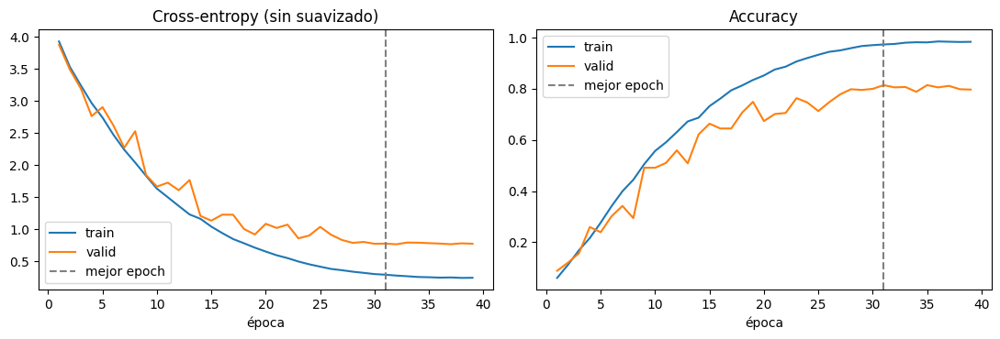

In [15]:
import numpy as np, matplotlib.pyplot as plt, cv2

# --- c) Curvas de entrenamiento ---
H = json.loads((settings.output_path / "history_cnn_custom.json").read_text())
h = H["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, t in zip(ax, ["loss", "acc"], ["Cross-entropy (sin suavizado)", "Accuracy"]):
    a.plot(h["epoch"], h[f"train_{k}"], label="train"); a.plot(h["epoch"], h[f"val_{k}"], label="valid")
    a.axvline(H["best_epoch"], ls="--", c="gray", label="mejor epoch"); a.set_title(t); a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()


- **Accuracy:** el modelo alcanza aproximadamente 98 % en entrenamiento, pero la validación se mantiene alrededor del 80-81 %. Esta diferencia de unos 17 puntos indica sobreajuste: aprende bien las imágenes de entrenamiento, pero le cuesta generalizar a imágenes nuevas.
- **Loss:** la pérdida de validación deja de mejorar claramente y se mantiene alrededor de 0.77 desde las últimas épocas. Esto coincide con el estancamiento de la accuracy.



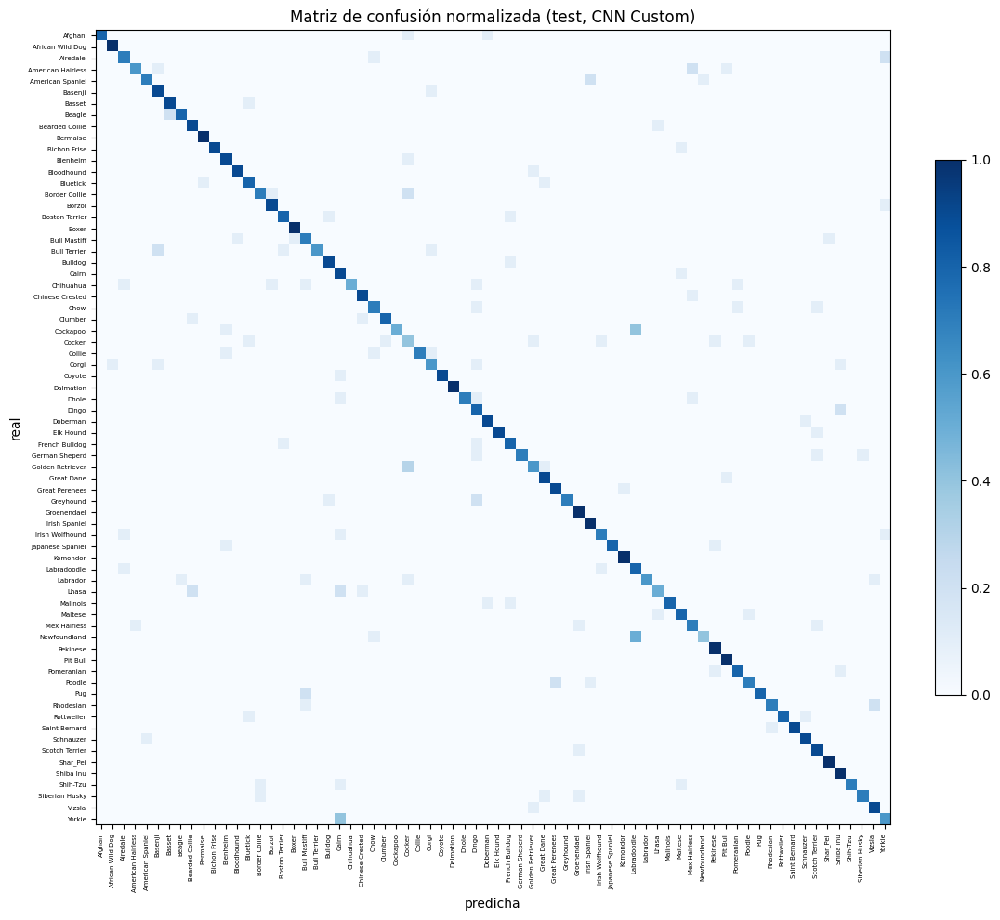

In [16]:

# --- a) y b) sobre test ---
classifier.set_active_model("cnn_custom")
classifier.evaluate_classifier()
ev = classifier.last_eval["cnn_custom:test"]
C, yt, yp, P = ev["classes"], ev["y_true"], ev["y_pred"], ev["probs"]
n = len(C)
cnt = np.bincount(yt * n + yp, minlength=n * n).reshape(n, n)
cmn = cnt / cnt.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(C, rotation=90, fontsize=5)
ax.set_yticks(range(n)); ax.set_yticklabels(C, fontsize=5)
ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title("Matriz de confusión normalizada (test, CNN Custom)")
plt.colorbar(im, fraction=0.03); plt.tight_layout(); plt.show()


Pares más confundidos (real -> predicha):
            real       predicha  veces  de
    Newfoundland    Labradoodle      5  10
          Yorkie          Cairn      4  10
        Cockapoo    Labradoodle      4  10
Golden Retriever         Cocker      3  10
           Lhasa Bearded Collie      2  10
          Poodle Great Perenees      2  10
           Lhasa          Cairn      2  10
             Pug   Bull Mastiff      2  10
       Greyhound          Dingo      2  10
           Dingo      Shiba Inu      2  10

Razas con peor F1:
            raza  precision  recall  soporte    f1
          Cocker      0.333     0.4       10 0.364
    Newfoundland      0.800     0.4       10 0.533
           Lhasa      0.714     0.5       10 0.588
     Labradoodle      0.471     0.8       10 0.593
          Yorkie      0.600     0.6       10 0.600
           Dingo      0.500     0.8       10 0.615
           Cairn      0.474     0.9       10 0.621
           Corgi      0.667     0.6       10 0.632
Golden

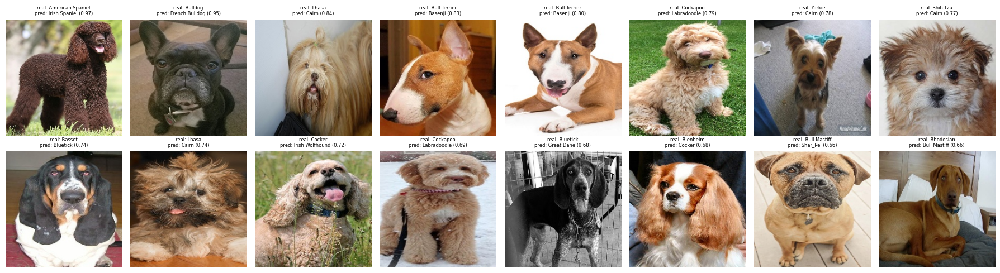

In [17]:

off = cnt.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:10], off.shape))[0]
print("Pares más confundidos (real -> predicha):")
print(pd.DataFrame([{"real": C[i], "predicha": C[j], "veces": int(off[i, j]), "de": int(cnt[i].sum())}
                    for i, j in top if off[i, j] > 0]).to_string(index=False))

tp = np.diag(cnt); sup = cnt.sum(1); pr = cnt.sum(0)
tabla = pd.DataFrame({"raza": C, "precision": tp / np.maximum(pr, 1), "recall": tp / sup, "soporte": sup})
tabla["f1"] = 2 * tabla.precision * tabla.recall / np.maximum(tabla.precision + tabla.recall, 1e-9)
print("\nRazas con peor F1:"); print(tabla.sort_values("f1").head(10).round(3).to_string(index=False))

# --- f) Errores con imagen y score ---
err = np.flatnonzero(yt != yp)
print(f"\nErrores en test: {len(err)} de {len(yt)}")
sel = err[np.argsort(-P[err, yp[err]])][:16]         # los errores donde el modelo estaba MÁS seguro
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax_, i in zip(axes.ravel(), sel):
    ax_.imshow(cv2.cvtColor(cv2.imread(ev["paths"][i]), cv2.COLOR_BGR2RGB)); ax_.axis("off")
    ax_.set_title(f"real: {C[yt[i]]}\npred: {C[yp[i]]} ({P[i, yp[i]]:.2f})", fontsize=6)
plt.tight_layout(); plt.show()

- **Razas con más dificultades:** Cocker (F1 0.364), Newfoundland (0.533), Lhasa (0.588), Labradoodle (0.593) y Yorkie (0.600).
- **Confusiones frecuentes:** Newfoundland → Labradoodle (5 de 10), Yorkie → Cairn (4 de 10) y Cockapoo → Labradoodle (4 de 10). Se repiten errores entre razas con características físicas similares.

Estas son posibles explicaciones:

1. **Falta de preentrenamiento:** la CNN aprende desde cero, utilizando unas 7.700 imágenes. En cambio, ResNet18 parte de características aprendidas previamente con un conjunto mucho más grande de imágenes.
2. **Arquitectura más pequeña:** tiene aproximadamente 2.5 millones de parámetros, frente a los 11.2 millones de ResNet18. Además, no utiliza conexiones residuales, que facilitan el entrenamiento de redes profundas.
3. **Dificultad para diferenciar razas:** muchas razas tienen características físicas similares. La CNN podría no aprender suficientes detalles para distinguirlas correctamente con la cantidad de imágenes disponible.

**Conclusión:** la CNN propia logra aprender las características del dataset, pero presenta sobreajuste y dificultades para generalizar. Sus resultados son inferiores a los de ResNet18, especialmente cuando se evalúa con fotografías nuevas.

## 8. Evaluación sobre el conjunto independiente

Métricas sobre el conjunto independiente para ambos modelos. Comparar con `test`
y discutir el cambio de dominio.

Métricas de test e independiente para A y B

In [17]:
import cv2, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt

INDEP = settings.dataset_path / "independent"
f = INDEP / "metadata_candidates.csv"
try:
    meta = pd.read_csv(f, encoding="utf-8-sig")
except UnicodeDecodeError:
    meta = pd.read_csv(f, encoding="cp1252")
ind = meta[meta.type == "single"].reset_index(drop=True)
paths_i, breeds_i = [INDEP / p for p in ind.path], ind.breed.tolist()

MODELOS = {"A (ResNet18 fine-tuned)": "resnet18_finetuned", "B (CNN propia)": "cnn_custom"}
filas_m, filas_d = [], []
for nombre, key in MODELOS.items():
    classifier.set_active_model(key)
    mt = classifier.evaluate_classifier()
    mi = classifier.evaluate_paths(paths_i, breeds_i, name="independent")
    Et, C = classifier.last_eval[f"{key}:test"], classifier.last_eval[f"{key}:test"]["classes"]
    m22 = np.isin(Et["y_true"], [C.index(b) for b in sorted(set(breeds_i))])
    acc22 = float((Et["y_true"][m22] == Et["y_pred"][m22]).mean())
    p = mi["accuracy"]; ic = 1.96 * np.sqrt(p * (1 - p) / len(paths_i))
    for conj, m in [("test", mt), ("independiente", mi)]:
        filas_m.append({"modelo": nombre, "conjunto": conj, **{k: round(v, 4) for k, v in m.items()}})
    filas_d.append({"modelo": nombre, "acc test (70 razas)": round(mt["accuracy"], 3),
                    "acc test (solo 22 razas)": round(acc22, 3), "acc independiente": round(p, 3),
                    "± IC95": round(ic, 3), "caída (pts)": round(100 * (acc22 - p), 1),
                    "retención": round(p / acc22, 2)})
classifier.set_active_model("resnet18_finetuned")
display(pd.DataFrame(filas_m)); display(pd.DataFrame(filas_d))

,modelo,conjunto,accuracy,precision,recall,specificity,f1
0,A (ResNet18 fine-tuned),test,0.9671,0.9688,0.9671,0.9995,0.9665
1,A (ResNet18 fine-tuned),independiente,0.6364,0.8951,0.6364,0.9965,0.7007
2,B (CNN propia),test,0.7957,0.8233,0.7957,0.9970,0.7962
3,B (CNN propia),independiente,0.2636,0.4178,0.2636,0.9892,0.2916


,modelo,acc test (70 razas),acc test (solo 22 razas),acc independiente,± IC95,caída (pts),retención
0,A (ResNet18 fine-tuned),0.967,0.973,0.636,0.090,33.6,0.65
1,B (CNN propia),0.796,0.768,0.264,0.082,50.5,0.34


Recall por raza y a dónde van los errores:

In [18]:
def recall_por_raza(key, split):
    E = classifier.last_eval[f"{key}:{split}"]; C = E["classes"]
    return pd.Series(E["y_true"] == E["y_pred"]).groupby([C[i] for i in E["y_true"]]).mean()

tabla = pd.DataFrame({"indep A": recall_por_raza("resnet18_finetuned", "independent"),
                      "indep B": recall_por_raza("cnn_custom", "independent"),
                      "test A": recall_por_raza("resnet18_finetuned", "test"),
                      "test B": recall_por_raza("cnn_custom", "test")}).dropna().round(2)
display(tabla.sort_values("indep A"))

for nombre, key in MODELOS.items():
    E = classifier.last_eval[f"{key}:independent"]; C = E["classes"]
    err = E["y_true"] != E["y_pred"]
    en22 = np.isin(E["y_pred"][err], [C.index(b) for b in set(breeds_i)])
    print(f"\n{nombre}: {err.sum()}/{len(err)} errores | predicen una raza fuera de las 22: {(~en22).sum()}")
    print(pd.Series([f"{C[a]} -> {C[b]}" for a, b in zip(E["y_true"][err], E["y_pred"][err])]).value_counts().head(8).to_string())

,indep A,indep B,test A,test B
Yorkie,0.0,0.0,1.0,0.6
Bloodhound,0.2,0.0,1.0,0.9
Vizsla,0.2,0.0,1.0,0.9
Chow,0.2,0.2,1.0,0.7
Poodle,0.4,0.0,1.0,0.7
Shih-Tzu,0.4,0.2,0.8,0.7
French Bulldog,0.4,0.0,0.9,0.8
German Sheperd,0.6,1.0,1.0,0.7
Rottweiler,0.6,0.4,1.0,0.8
Golden Retriever,0.6,0.0,1.0,0.6



A (ResNet18 fine-tuned): 40/110 errores | predicen una raza fuera de las 22: 32
Vizsla -> Rhodesian          4
Bloodhound -> Rhodesian      2
Poodle -> Airedale           2
Yorkie -> Cocker             2
Shih-Tzu -> Lhasa            2
Beagle -> Basset             1
French Bulldog -> Bulldog    1
Pug -> Shar_Pei              1

B (CNN propia): 81/110 errores | predicen una raza fuera de las 22: 56
Vizsla -> Rhodesian                 3
Beagle -> Rhodesian                 2
Rottweiler -> Doberman              2
Yorkie -> Rhodesian                 2
Bloodhound -> Rhodesian             2
Bloodhound -> Bluetick              2
Lhasa -> Shih-Tzu                   2
Saint Bernard -> Chinese Crested    2


Grillas de errores

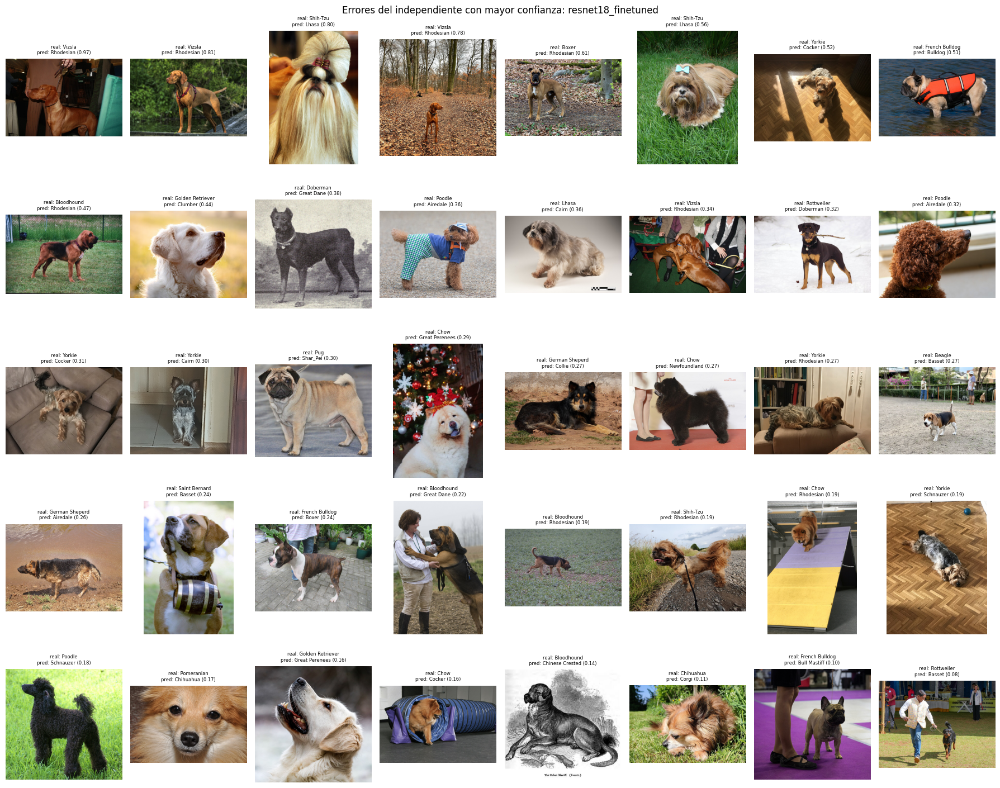

In [20]:
def grilla_errores(key, max_n=24):
    E = classifier.last_eval[f"{key}:independent"]; C = E["classes"]
    err = np.flatnonzero(E["y_true"] != E["y_pred"])
    err = err[np.argsort(-E["probs"][err, E["y_pred"][err]])][:max_n]
    nrows = int(np.ceil(len(err) / 8))
    fig, axes = plt.subplots(nrows, 8, figsize=(18, 2.9 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), err):
        ax.imshow(cv2.cvtColor(cv2.imread(E["paths"][i]), cv2.COLOR_BGR2RGB))
        ax.set_title(f"real: {C[E['y_true'][i]]}\npred: {C[E['y_pred'][i]]} ({E['probs'][i, E['y_pred'][i]]:.2f})", fontsize=6)
    fig.suptitle(f"Errores del independiente con mayor confianza: {key}"); plt.tight_layout(); plt.show()

grilla_errores("resnet18_finetuned", 40)


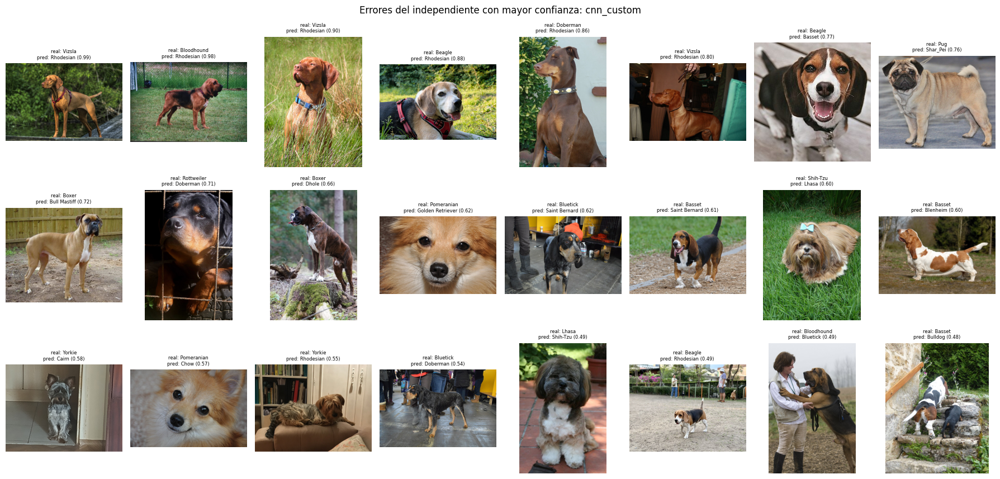

In [21]:
grilla_errores("cnn_custom", 24)


¿Importa el preprocesamiento (resize contra pad)?

In [22]:
from lib.preprocessing import preprocess_to_tensor
def acc_con_modo(key, mode):
    classifier.set_active_model(key)
    model, y = classifier._inference_model(), classifier.last_eval[f"{key}:independent"]["y_true"]
    dev, pred = torch.device("cuda" if torch.cuda.is_available() else "cpu"), []
    try:
        model.to(dev)
        with torch.no_grad():
            for p in paths_i:
                x = preprocess_to_tensor(cv2.imread(str(p)), classifier.image_size, mode=mode).to(dev)
                pred.append(model(x).argmax(1).item())
    finally:
        model.to("cpu")
    return round(float((np.array(pred) == y).mean()), 3)

print({k: {m: acc_con_modo(v, m) for m in ["resize", "pad"]} for k, v in MODELOS.items()})
classifier.set_active_model("resnet18_finetuned")

{'A (ResNet18 fine-tuned)': {'resize': 0.636, 'pad': 0.582}, 'B (CNN propia)': {'resize': 0.264, 'pad': 0.245}}


## 9. Embeddings de los modelos entrenados

TO-DO:
- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).

In [23]:
import torch
from lib.preprocessing import preprocess_to_tensor

NOMBRES = {"baseline": "Baseline (ImageNet)", "resnet18_finetuned": "Modelo A (fine-tuned)", "cnn_custom": "Modelo B (CNN propia)"}
CONJ = [("train", train_p), ("valid", valid_p), ("test", test_p), ("indep", indep_p), ("none", none_p)]

def embeddings_modelo(key, nombre, paths, bs=128):
    cache = EMB_DIR / f"{key}__{nombre}.npy"          # si reentrenás un modelo, borrá output/embeddings
    if cache.exists():
        E = np.load(cache); assert len(E) == len(paths), f"Caché desactualizado: {cache}"; return E
    classifier.set_active_model(key)
    model, dev, out = classifier._inference_model(), torch.device("cuda" if torch.cuda.is_available() else "cpu"), []
    try:
        model.to(dev)
        with torch.no_grad():
            for s in tqdm(range(0, len(paths), bs), desc=f"{key}/{nombre}"):
                x = torch.cat([preprocess_to_tensor(cv2.imread(str(p)), classifier.image_size) for p in paths[s:s + bs]]).to(dev)
                out.append(torch.nn.functional.normalize(model.embed(x).float(), dim=1).cpu().numpy())
    finally:
        model.to("cpu")
    E = np.concatenate(out).astype(np.float32); np.save(cache, E)
    return E

EMBS = {"baseline": {"train": G, "valid": Qv, "test": Qt, "indep": Qi, "none": Qn}}
for key in ["resnet18_finetuned", "cnn_custom"]:
    EMBS[key] = {nombre: embeddings_modelo(key, nombre, paths) for nombre, paths in CONJ}

# Verificación: el camino por lotes == la función que usa la app (extract_custom_embedding)
for key in ["resnet18_finetuned", "cnn_custom"]:
    classifier.set_active_model(key)
    a = np.array(classifier.extract_custom_embedding(cv2.imread(str(test_p[0]))))
    print(f"{key:20s} dim {len(a)} | max|diff| vs. lote: {np.abs(a - EMBS[key]['test'][0]).max():.1e}")

resnet18_finetuned   dim 512 | max|diff| vs. lote: 7.5e-05
cnn_custom           dim 512 | max|diff| vs. lote: 4.7e-05


In [24]:
tabla9 = pd.DataFrame([{"embeddings": NOMBRES[m], "consultas": c,
                        **{k: round(float(v), 4) for k, v in evaluar(E[s], y, E["train"], "cosine").items()}}
                       for m, E in EMBS.items() for c, s, y in [("test", "test", ty), ("independiente", "indep", iy)]]
                      ).rename(columns={"NDCG@k": "NDCG@10", "P@k": "P@10"})
tabla9

,embeddings,consultas,NDCG@10,P@10,acc_raza
0,Baseline (ImageNet),test,0.8735,0.8597,0.9329
1,Baseline (ImageNet),independiente,0.6203,0.6045,0.7000
2,Modelo A (fine-tuned),test,0.9587,0.9569,0.9714
3,Modelo A (fine-tuned),independiente,0.6482,0.6464,0.6727
4,Modelo B (CNN propia),test,0.7704,0.7616,0.8014
5,Modelo B (CNN propia),independiente,0.2665,0.2636,0.2455


- **En test:** el Modelo A obtuvo los mejores resultados de búsqueda, superando al baseline. Encontró imágenes de la misma raza con mayor precisión. El Modelo B tuvo el rendimiento más bajo.

- **Conjunto independiente:** el Modelo A y el baseline obtuvieron resultados similares. Esto indica que el fine-tuning mejora la búsqueda con imágenes del dataset original, pero no demuestra una mejora con fotografías nuevas.

- **Modelo B:** tuvo una caída importante en el conjunto independiente. Esto indica que sus embeddings tienen dificultades para reconocer similitudes cuando se utilizan imágenes diferentes a las del entrenamiento.

- **Búsqueda vs. clasificación:** en el Modelo A, ambos métodos obtuvieron resultados similares. No se observa una diferencia importante entre predecir la raza mediante vecinos similares o mediante el clasificador directo.

Para no usar test en la decisión, se comparó sobre validación (690 consultas):

In [38]:
pd.DataFrame([{"embeddings": NOMBRES[m], **{k: round(float(v), 4) for k, v in evaluar(E["valid"], vy, E["train"], "cosine").items()}}
              for m, E in EMBS.items()]).rename(columns={"NDCG@k": "NDCG@10", "P@k": "P@10"})

,embeddings,NDCG@10,P@10,acc_raza
0,Baseline (ImageNet),0.8637,0.8519,0.9362
1,Modelo A (fine-tuned),0.9491,0.9459,0.9667
2,Modelo B (CNN propia),0.7818,0.7735,0.8362


- **Resultados:** la validación y el test muestran el mismo orden de rendimiento: Modelo A, baseline y Modelo B. El Modelo A obtuvo los mejores resultados, mejorando el NDCG@10 y encontrando correctamente 21 imágenes más que el baseline.

- **Modelo elegido:** se selecciona el Modelo A (`resnet18_finetuned`) para realizar las búsquedas.

- **Motivos:** obtuvo los mejores resultados en validación y test, tiene un costo computacional similar al baseline y permite reutilizar el modelo entrenado anteriormente, sin necesidad de descargar nuevamente los pesos de ImageNet.

- **Limitación:** su ventaja se observa principalmente con imágenes similares a las del dataset de entrenamiento. Con fotografías nuevas, no mostró una mejora significativa frente al baseline.

###Visualizacion t-SNE

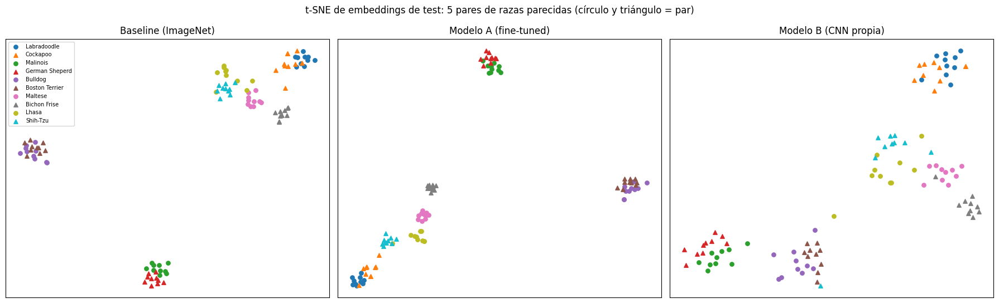

In [34]:
from sklearn.manifold import TSNE


PARES = [("Labradoodle", "Cockapoo"), ("Malinois", "German Sheperd"), ("Bulldog", "Boston Terrier"),
         ("Maltese", "Bichon Frise"), ("Lhasa", "Shih-Tzu")]
razas = [r for par in PARES for r in par]
assert all(r in CI for r in razas), [r for r in razas if r not in CI]
mask, cm_ = np.isin(ty, [CI[r] for r in razas]), plt.get_cmap("tab10")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (key, E) in zip(axes, EMBS.items()):
    Z = TSNE(perplexity=15, init="pca", metric="cosine", random_state=0).fit_transform(E["test"][mask])
    for i, r in enumerate(razas):
        m = ty[mask] == CI[r]
        ax.scatter(Z[m, 0], Z[m, 1], s=28, color=cm_(i), marker="o" if i % 2 == 0 else "^", label=r)
    ax.set_title(NOMBRES[key]); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(fontsize=7)
plt.suptitle("t-SNE de embeddings de test: 5 pares de razas parecidas (círculo y triángulo = par)"); plt.tight_layout(); plt.show()


- **Razas similares:** los tres modelos confunden especialmente las mismas parejas: Labradoodle/Cockapoo, Malinois/Pastor Alemán y Bulldog/Boston Terrier. Esto coincide con las confusiones observadas durante la clasificación.

- **Modelo A (ResNet18):** logra formar grupos de razas más definidos y separados. Se destacan las mejoras al distinguir Maltese, Bichon, Lhasa y Shih-Tzu respecto del baseline.

- **Modelo B (CNN propia):** presenta los grupos más mezclados y dispersos, especialmente entre Lhasa, Shih-Tzu y Maltese.

- **Conclusión:** ResNet18 genera embeddings que representan mejor las diferencias entre razas. Esto coincide con sus mejores resultados en las evaluaciones anteriores.

### Calibración del umbral de similitud

In [37]:
def tabla_compromiso(E, frrs=(0.0, 0.02, 0.05, 0.10, 0.20)):
    G_ = E["train"]
    bv, bn = (E["valid"] @ G_.T).max(1), (E["none"] @ G_.T).max(1)
    res = {}
    for nombre, Q, qy in [("test", E["test"], ty), ("indep", E["indep"], iy)]:
        S = Q @ G_.T
        pred, best = predecir(S, np.argsort(-S, axis=1)[:, :10])
        res[nombre] = (best, pred == np.array(CLASSES)[qy])
    filas = []
    for frr in frrs:
        t = float(np.quantile(bv, frr))
        f = {"% valid rechazado": frr, "umbral": round(t, 3), "equiv. l2": round(1 / (1 + np.sqrt(max(2 - 2 * t, 0))), 3)}
        for nombre, (best, ok) in res.items():
            a = best >= t
            f[f"cobertura {nombre}"] = round(a.mean(), 3)
            f[f"acc aceptadas {nombre}"] = round(ok[a].mean(), 3) if a.any() else np.nan
        f[f"sin perros rechazadas (de {len(bn)})"] = round((bn < t).mean(), 2)
        filas.append(f)
    return pd.DataFrame(filas)

ELEGIDO = "resnet18_finetuned"       # <- EMBEDDING_MODEL
tabla_compromiso(EMBS[ELEGIDO])

,% valid rechazado,umbral,equiv. l2,cobertura test,acc aceptadas test,cobertura indep,acc aceptadas indep,sin perros rechazadas (de 9)
0,0.00,0.788,0.606,1.000,0.971,0.791,0.747,0.67
1,0.02,0.823,0.627,0.976,0.974,0.518,0.860,1.00
2,0.05,0.842,0.640,0.959,0.975,0.418,0.891,1.00
3,0.10,0.855,0.650,0.911,0.975,0.364,0.925,1.00
4,0.20,0.870,0.662,0.826,0.979,0.273,1.000,1.00


- **Umbral elegido: 0.788 (coseno):** es el menor score observado en validación, por lo que no rechaza ninguna consulta legítima. Se eligió porque permite aceptar más fotos reales que el umbral 0.823.
- **En test:** no mejora la accuracy (se mantiene en 97.1 %), ya que los errores del modelo tienen scores altos. Su función es detectar imágenes que no se parecen a las de la galería, no corregir confusiones entre razas.
- **En el conjunto independiente:** con este umbral se acepta el 79 % de las imágenes (aproximadamente 87 de 110). Es una cobertura mayor que con 0.823, que solo aceptaba el 52 %.
- **Imágenes sin perros:** se rechazan 6 de las 9 imágenes. Las otras 3 son aceptadas, por lo que el umbral no detecta todos los casos fuera del dominio esperado.
- **Limitaciones:** el control de imágenes sin perros contiene solo 9 fotos, por lo que es una muestra pequeña. Además, el umbral es válido para este modelo y la métrica coseno; si se cambia el modelo de embeddings, hay que calibrarlo nuevamente.

**Configuración final de la búsqueda:** `EMBEDDING_MODEL=resnet18_finetuned`, `EMBEDDING_DIM=512`,
`SIMILARITY_METRIC=cosine`, `SIMILARITY_THRESHOLD=0.788`, `TOP_K=10`.

### Validacion de sistema de deteccion YOLO


Se probó un detector YOLO preentrenado en COCO (clase `dog`) sobre el conjunto independiente: 110 imágenes de un
perro, 10 escenas con varios perros u otros elementos y 9 imágenes sin perros (gatos, caballos y aves). Cada caja se
recorta y se clasifica con el Modelo A.

In [51]:
INDEP = settings.dataset_path / "independent"
f = INDEP / "metadata.csv" if (INDEP / "metadata.csv").exists() else INDEP / "metadata_candidates.csv"
try:
    meta = pd.read_csv(f, encoding="utf-8-sig")
except UnicodeDecodeError:
    meta = pd.read_csv(f, encoding="cp1252")

classifier.set_active_model("resnet18_finetuned")
detection = build_detection(settings, classifier)
conf0 = detection.conf_threshold

grupos = {"un perro": meta[meta.type == "single"], "varios perros / escenas": meta[meta.type == "multi"],
          "sin perros": meta[meta.type == "none"]}
filas = []
for conf in [0.10, 0.25, 0.50]:
    detection.conf_threshold = conf
    for nombre, g in grupos.items():
        n = np.array([len(detection.detect_dogs(cv2.imread(str(INDEP / p)))) for p in g.path])
        filas.append({"conf": conf, "grupo": nombre, "imágenes": len(n), "detecciones totales": int(n.sum()),
                      "imágenes con ≥1 detección": int((n > 0).sum()), "imágenes con exactamente 1": int((n == 1).sum()),
                      "máx. detecciones en una imagen": int(n.max())})
detection.conf_threshold = conf0
tabla_e3 = pd.DataFrame(filas)
display(tabla_e3)
print("YOLO_CONF_THRESHOLD actual (.env):", conf0)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


,conf,grupo,imágenes,detecciones totales,imágenes con ≥1 detección,imágenes con exactamente 1,máx. detecciones en una imagen
0,0.10,un perro,110,104,99,95,3
1,0.10,varios perros / escenas,10,23,10,2,4
2,0.10,sin perros,9,0,0,0,0
3,0.25,un perro,110,99,97,95,2
4,0.25,varios perros / escenas,10,20,10,4,4
5,0.25,sin perros,9,0,0,0,0
6,0.50,un perro,110,87,86,85,2
7,0.50,varios perros / escenas,10,18,8,2,4
8,0.50,sin perros,9,0,0,0,0


YOLO_CONF_THRESHOLD actual (.env): 0.25



- **Sin perros:** con ningún umbral el detector devuelve cajas para gatos, caballos o aves (lista vacía en las 9
  imágenes). Por eso el umbral se elige según cuántos perros se encuentran.
- **Un perro:** con 0.50 se pierden 11 imágenes más que con 0.25 (86 contra 97). Con 0.10 se encuentran solo 2 más (99),
  pero aparecen cajas de más: 4 imágenes con 2 o 3 detecciones, contra 2 con 0.25.
- **Elegido: `YOLO_CONF_THRESHOLD=0.25`** (el valor por defecto): es el mejor compromiso entre perros encontrados y cajas
  repetidas. Aun así, 13 de las 110 imágenes de un perro (12 %) quedan sin detección.
- **Varios perros:** con 0.25 se detecta algún perro en las 10 escenas (20 detecciones en total, hasta 4 por imagen),
  y las personas no se detectan como perros.
- **Clasificación de los recortes:** en recortes chicos o ambiguos la probabilidad de la raza es baja (por ejemplo, 0.10 a
  0.18 en algunas escenas) **[verificar]**, y la app devuelve igualmente una raza, porque no se implementó el
  umbral opcional `unknown`.

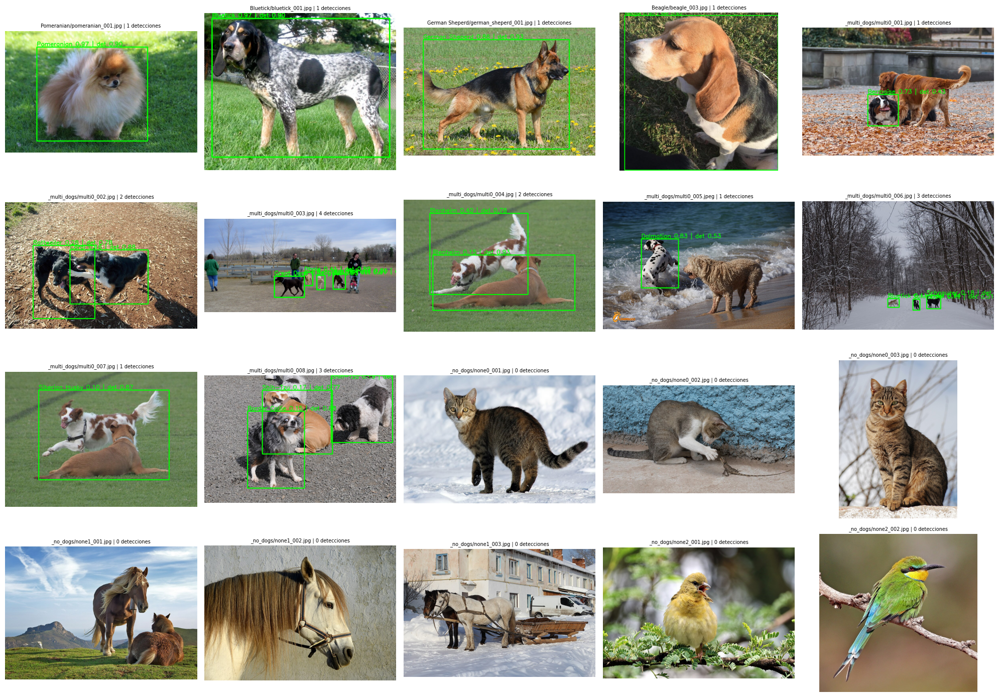

In [52]:
CONF = 0.25                                   # YOLO_CONF_THRESHOLD
detection.conf_threshold = CONF
sel = (list(grupos["un perro"].path.sample(4, random_state=0)) + list(grupos["varios perros / escenas"].path)[:8]
       + list(grupos["sin perros"].path)[:8])
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax in axes.ravel():
    ax.axis("off")
for ax, p in zip(axes.ravel(), sel):
    orig = cv2.imread(str(INDEP / p)); img = orig.copy(); h, w = img.shape[:2]
    dets = detection.detect_dogs(orig)
    for (x1, y1, x2, y2), c in dets:
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
        breed, s = detection.classify_detected_dog(orig[y1:y2, x1:x2])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), max(2, w // 200))
        cv2.putText(img, f"{breed} {s:.2f} | det {c:.2f}", (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, w / 1000), (0, 255, 0), 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f"{p} | {len(dets)} detecciones", fontsize=7)
plt.tight_layout(); plt.show()
detection.conf_threshold = conf0

In [53]:
ind = grupos["un perro"]
ok_full = ok_crop = sin_det = 0
for p, b in zip(ind.path, ind.breed):
    img = cv2.imread(str(INDEP / p)); h, w = img.shape[:2]
    full, _ = detection.classify_detected_dog(img)
    dets = detection.detect_dogs(img)
    if dets:
        (x1, y1, x2, y2), _ = dets[0]                                  # el perro de mayor confianza
        crop_pred, _ = detection.classify_detected_dog(img[max(0, y1):min(h, y2), max(0, x1):min(w, x2)])
    else:
        sin_det += 1; crop_pred = full
    ok_full += (full == b); ok_crop += (crop_pred == b)
print(f"Imagen completa: {ok_full / len(ind):.3f} | recorte del perro de mayor confianza: {ok_crop / len(ind):.3f} | "
      f"sin detección: {sin_det} de {len(ind)} (CONF={detection.conf_threshold})")

Imagen completa: 0.636 | recorte del perro de mayor confianza: 0.709 | sin detección: 13 de 110 (CONF=0.25)



**Recorte contra imagen completa.** Con el mismo clasificador, sobre las 110 imágenes de un perro, la accuracy es 0.636
con la imagen completa y 0.709 con el recorte de YOLO (78 contra 70 imágenes; las 13 sin detección usan la imagen
completa). La diferencia son 8 imágenes y el margen de error es de ±9 puntos. Una posible
explicación, es que el recorte elimina fondo y personas y se parece más a las imágenes centradas del dataset.

## 10. Análisis de errores



Cada error significa que el modelo no reconoció la raza correcta y predijo otra. Las figuras muestran los 16 errores con mayor confianza de cada modelo.


== Modelo A (fine-tuned): 10 razas con peor F1 en test ==


,raza,FP,FN,precision,recall,F1
50,Malinois,0,4,1.000,0.6,0.750
20,Bulldog,2,2,0.800,0.8,0.800
16,Boston Terrier,2,2,0.800,0.8,0.800
66,Shih-Tzu,1,2,0.889,0.8,0.842
47,Labradoodle,2,1,0.818,0.9,0.857
45,Japanese Spaniel,0,2,1.000,0.8,0.889
4,American Spaniel,1,1,0.900,0.9,0.900
26,Cockapoo,1,1,0.900,0.9,0.900
36,French Bulldog,1,1,0.900,0.9,0.900
49,Lhasa,1,1,0.900,0.9,0.900


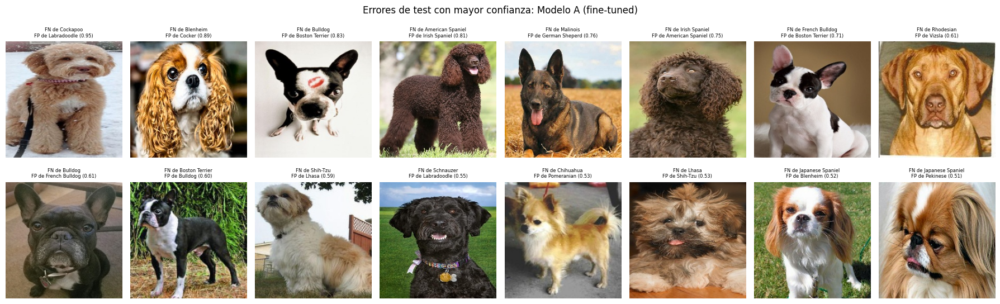


== Modelo B (CNN propia): 10 razas con peor F1 en test ==


,raza,FP,FN,precision,recall,F1
27,Cocker,8,6,0.333,0.4,0.364
53,Newfoundland,1,6,0.800,0.4,0.533
49,Lhasa,2,5,0.714,0.5,0.588
47,Labradoodle,9,2,0.471,0.8,0.593
69,Yorkie,4,4,0.600,0.6,0.600
33,Dingo,8,2,0.500,0.8,0.615
21,Cairn,10,1,0.474,0.9,0.621
29,Corgi,3,4,0.667,0.6,0.632
38,Golden Retriever,3,4,0.667,0.6,0.632
18,Bull Mastiff,5,3,0.583,0.7,0.636


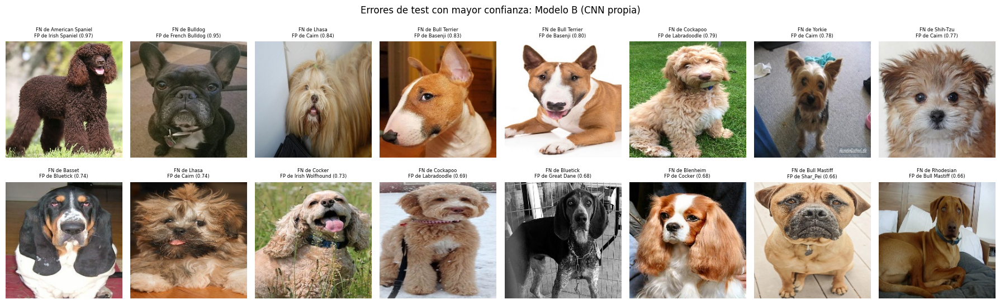

In [28]:
def tabla_por_raza(key):
    classifier.set_active_model(key); classifier.evaluate_classifier()
    E = classifier.last_eval[f"{key}:test"]; C, n = E["classes"], len(E["classes"])
    cm = np.bincount(E["y_true"] * n + E["y_pred"], minlength=n * n).reshape(n, n)
    tp = np.diag(cm); fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    prec, rec = tp / np.maximum(tp + fp, 1), tp / np.maximum(tp + fn, 1)
    return pd.DataFrame({"raza": C, "FP": fp, "FN": fn, "precision": prec, "recall": rec,
                         "F1": 2 * prec * rec / np.maximum(prec + rec, 1e-9)}).sort_values("F1").round(3)

def grilla_fp_fn(key, n=16):
    E = classifier.last_eval[f"{key}:test"]; C = E["classes"]
    err = np.flatnonzero(E["y_true"] != E["y_pred"])
    err = err[np.argsort(-E["probs"][err, E["y_pred"][err]])][:n]            # los errores con más confianza
    fig, axes = plt.subplots(2, 8, figsize=(18, 5.8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), err):
        ax.imshow(cv2.cvtColor(cv2.imread(E["paths"][i]), cv2.COLOR_BGR2RGB))
        ax.set_title(f"FN de {C[E['y_true'][i]]}\nFP de {C[E['y_pred'][i]]} ({E['probs'][i, E['y_pred'][i]]:.2f})", fontsize=6)
    plt.suptitle(f"Errores de test con mayor confianza: {NOMBRES[key]}"); plt.tight_layout(); plt.show()

for key in ["resnet18_finetuned", "cnn_custom"]:
    print(f"\n== {NOMBRES[key]}: 10 razas con peor F1 en test =="); display(tabla_por_raza(key).head(10))
    grilla_fp_fn(key)


**Modelo A (23 errores de 700).**

Las razas con peor F1 fueron Malinois (0.750), Bulldog y Boston Terrier (0.800), Shih-Tzu (0.842), Labradoodle (0.857) y Japanese Spaniel (0.889).

La mayoría de los errores son confusiones entre razas parecidas:
- Malinois → Pastor Alemán.
- Bulldog ↔ Boston Terrier ↔ Bulldog Francés.
- Shih-Tzu ↔ Lhasa.
- Cockapoo → Labradoodle.
- American Spaniel ↔ Irish Spaniel.

**Modelo B (143 errores de 700).**

Las razas con peor F1 fueron Cocker (0.364), Newfoundland (0.533), Lhasa (0.588), Labradoodle (0.593), Yorkie (0.600), Dingo (0.615) y Cairn (0.621).

Presenta errores más marcados y algunos con mucha confianza (hasta 0.97). Por ejemplo, Bull Terrier → Basenji, Bluetick → Great Dane y varios perros de pelo largo → Cairn. Podría estar dando demasiado peso al color, al pelaje y a la forma de las orejas

Se observan dos problemas:
- **Muchas predicciones incorrectas hacia algunas razas:** Cairn, Labradoodle, Cocker y Dingo reciben predicciones de otras razas. Por ejemplo, varios Lhasa, Yorkie y Shih-Tzu se clasifican como Cairn.
- **Dificultad para reconocer algunas razas:** Newfoundland, Lhasa y Yorkie presentan varios falsos negativos.

**Posibles causas de los errores**

1. **Razas parecidas:** algunas comparten características físicas, como el tipo de pelaje, el tamaño o la forma de la cara. Esto dificulta distinguirlas. Por ejemplo, Cockapoo/Labradoodle, Bulldog/Boston Terrier y Shih-Tzu/Lhasa.
2. **Posibles errores en las etiquetas:** algunas imágenes etiquetadas como Bulldog parecen corresponder a Boston Terrier o Bulldog Francés. Sin embargo, no se revisaron formalmente las etiquetas, por lo que es solo una observación visual.
3. **Modelo A:** los errores analizados muestran perros bien encuadrados y fondos variados. Esto sugiere que el parecido entre razas tiene más importancia que la pose o el fondo en estos casos.
4. **Modelo B:** al no utilizar preentrenamiento y tener 2.5 millones de parámetros, podría aprender características menos útiles para diferenciar las razas. También presenta errores con alta confianza.
5. **Muestra pequeña:** hay solo 10 imágenes por raza en test. Por eso, uno o dos errores pueden cambiar bastante las métricas y el orden de las razas con peor desempeño.

## 11. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.

In [29]:
import time, os
from pathlib import Path

def cargar(key):
    if key == "baseline":
        return similarity._baseline_model()
    classifier.set_active_model(key)
    return classifier._inference_model()

x1 = preprocess_to_tensor(cv2.imread(str(test_p[0])), classifier.image_size)
filas = []
for key in EMBS:
    m = cargar(key).cpu().eval()
    params = sum(q.numel() for q in m.parameters())
    ruta = None if key == "baseline" else Path(classifier.checkpoints[key])
    mb = (ruta.stat().st_size if ruta is not None and ruta.exists() else params * 4) / 1e6   # baseline: fp32 estimado
    with torch.inference_mode():
        for _ in range(5):
            m(x1)                                                                         # calentamiento
        t = []
        for _ in range(50):
            t0 = time.perf_counter(); m(x1); t.append(time.perf_counter() - t0)
    hist = settings.output_path / f"history_{key}.json"
    filas.append({"modelo": NOMBRES[key], "parámetros (M)": round(params / 1e6, 2), "tamaño (MB)": round(mb, 1),
                  "CPU ms/img": round(1000 * float(np.median(t)), 1), "dim emb": 512,
                  "entrenamiento (s)": json.loads(hist.read_text())["seconds"] if hist.exists() else 0})
tabla11 = pd.DataFrame(filas); display(tabla11)
print(f"Medido con {os.cpu_count()} núcleos de CPU (Colab), batch 1, solo el forward del modelo (sin lectura de imagen).")

,modelo,parámetros (M),tamaño (MB),CPU ms/img,dim emb,entrenamiento (s)
0,Baseline (ImageNet),11.18,44.7,23.3,512,0
1,Modelo A (fine-tuned),11.21,44.9,23.7,512,0
2,Modelo B (CNN propia),2.51,10.1,9.5,512,0


Medido con 12 núcleos de CPU (Colab), batch 1, solo el forward del modelo (sin lectura de imagen).


## 12. Comparación y elección final

TO-DO:
- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.

In [44]:
cls = pd.DataFrame(filas_m).set_index(["modelo", "conjunto"])
nom_cls = {"resnet18_finetuned": "A (ResNet18 fine-tuned)", "cnn_custom": "B (CNN propia)"}
ret, costo = tabla9.set_index(["embeddings", "consultas"]), tabla11.set_index("modelo")
filas = []
for key in ["baseline", "resnet18_finetuned", "cnn_custom"]:
    n = NOMBRES[key]; f = {"modelo / embeddings": n}
    for c, tag in [("test", "test"), ("independiente", "indep")]:
        if key in nom_cls:
            f[f"clasif. acc {tag}"] = cls.loc[(nom_cls[key], c), "accuracy"]
            f[f"clasif. F1 {tag}"] = cls.loc[(nom_cls[key], c), "f1"]
        f[f"búsq. NDCG@10 {tag}"] = ret.loc[(n, c), "NDCG@10"]
        f[f"búsq. acc raza {tag}"] = ret.loc[(n, c), "acc_raza"]
    f.update(costo.loc[n, ["parámetros (M)", "tamaño (MB)", "CPU ms/img"]].to_dict())
    filas.append(f)
tabla_final = pd.DataFrame(filas).round(4).set_index("modelo / embeddings").T
tabla_final

modelo / embeddings,Baseline (ImageNet),Modelo A (fine-tuned),Modelo B (CNN propia)
búsq. NDCG@10 test,0.8735,0.9587,0.7704
búsq. acc raza test,0.9329,0.9714,0.8014
búsq. NDCG@10 indep,0.6203,0.6482,0.2665
búsq. acc raza indep,0.7000,0.6727,0.2455
parámetros (M),11.1800,11.2100,2.5100
tamaño (MB),44.7000,44.9000,10.1000
CPU ms/img,23.3000,23.7000,9.5000
clasif. acc test,NaN,0.9671,0.7957
clasif. F1 test,NaN,0.9665,0.7962
clasif. acc indep,NaN,0.6364,0.2636


### 12.1 Tabla comparativa

| | Baseline (ImageNet) | Modelo A (fine-tuned) | Modelo B (CNN propia) |
|---|---|---|---|
| **Clasificación (Etapas 2 y 3)** | | | |
| Accuracy, test | — | 0.9671 | 0.7957 |
| F1 macro, test | — | 0.9665 | 0.7962 |
| Accuracy, independiente | — | 0.6364 | 0.2636 |
| F1 macro, independiente* | — | 0.7007 | 0.2916 |
| **Búsqueda (Etapa 1)** | | | |
| NDCG@10, test | 0.8735 | 0.9587 | 0.7704 |
| Accuracy de raza por vecinos, test | 0.9329 | 0.9714 | 0.8014 |
| NDCG@10, independiente | 0.6203 | 0.6482 | 0.2665 |
| Accuracy de raza por vecinos, independiente | 0.7000 | 0.6727 | 0.2455 |
| **Costo** | | | |
| Parámetros (M) | 11.18 | 11.21 | 2.51 |
| Tamaño (MB) | 44.7 | 44.9 | 10.1 |
| Latencia CPU (ms/img) | 23.3 | 23.7 | 9.5 |

*El conjunto independiente tiene solo 22 razas, por lo que el F1 macro se calcula sobre esas razas y puede ser optimista. Para comparar, es más representativa la accuracy. Los resultados tienen un margen de error aproximado de ±1-2 puntos en test y ±9 en el independiente. La latencia se midió en CPU, con 12 núcleos de Colab. El baseline no realiza clasificación directa, por eso no tiene esas métricas.*



### 12.2 Modelos elegidos para la aplicación

**Clasificación (Etapas 2 y 3): Modelo A (`resnet18_finetuned`).**

- Obtuvo mejores resultados que la CNN propia: 96.7 % de accuracy en test y 63.6 % en el independiente, frente a 79.6 % y 26.4 % de B.
- Aunque B es más pequeño y rápido, pierde demasiada precisión. Por eso se eligió el Modelo A.

**Búsqueda por similitud (Etapa 1): Modelo A (`resnet18_finetuned`).**

- Obtuvo los mejores resultados en validación y test, superando al baseline y al Modelo B.
- Tiene un costo similar al baseline y permite reutilizar el modelo entrenado en la Etapa 2.
- En el conjunto independiente, A y el baseline obtuvieron resultados similares. Por lo tanto, la ventaja del fine-tuning se observa principalmente con imágenes parecidas a las del dataset original.
- La galería final utiliza 7686 imágenes de entrenamiento, embeddings de 512 dimensiones y métrica coseno, con `SIMILARITY_THRESHOLD=0.788`.


### 12.3 Búsqueda por similitud vs. clasificación

| | Búsqueda por similitud | Clasificación supervisada |
|---|---|---|
| **Ventajas** | Permite agregar imágenes o razas sin reentrenar. Se pueden ver las imágenes más parecidas y utilizar un umbral para rechazar consultas. | Respuesta directa y rápida. No necesita mantener una galería y devuelve una probabilidad por raza. |
| **Limitaciones** | Necesita guardar una galería de imágenes. La búsqueda puede volverse más lenta al crecer la base y requiere configurar parámetros adicionales. | Solo reconoce las 70 razas entrenadas. Para agregar otra raza hay que reentrenar y siempre predice alguna, aunque la imagen no pertenezca a ninguna de ellas. |
| **Conviene cuando** | Se necesitan agregar razas, consultar imágenes similares o rechazar entradas desconocidas. | Las razas son siempre las mismas y se busca una respuesta rápida. |

**Resultados de nuestro proyecto:**

- Con el Modelo A, la búsqueda por vecinos y la clasificación obtuvieron resultados similares: 97.1 % y 96.7 % en test.
- En el conjunto independiente también fueron parecidos: 67.3 % y 63.6 %. La diferencia es pequeña y no permite afirmar que un método sea mejor.
- El baseline, sin fine-tuning, obtuvo 70 % en el independiente, incluso por encima del Modelo A (63.6 %). La diferencia es de solo 7 imágenes, por lo que no es concluyente.
- El fine-tuning mejora los resultados con imágenes del dataset original, pero no mostró una mejora clara con fotografías nuevas.




### 12.4 Comparación de costos y limitaciones

- **Precisión:** el Modelo A supera a B por 17 puntos en test y 37 puntos en el independiente. Sin embargo, ambos pierden rendimiento con fotografías nuevas.
- **Velocidad:** B es aproximadamente 2.5 veces más rápido que A (9.5 ms frente a 23.7 ms por imagen). De todas formas, A mantiene una latencia baja.
- **Indexación:** construir la galería puede llevar bastante tiempo. En Docker sobre Windows, procesar 210 imágenes tardó 447 segundos. Por eso, se generó la galería en Colab y luego se cargó en la aplicación.
- **Memoria:** B ocupa 10.1 MB y A 44.9 MB. La búsqueda también necesita almacenar la galería (aproximadamente 15.7 MB) y utilizar PostgreSQL con pgvector.
- **Entrenamiento:** A aprovecha pesos preentrenados y requiere un ajuste adicional. B se entrenó desde cero y necesitó aproximadamente 19 minutos, además de pruebas para ajustar su arquitectura.
- **Complejidad:** la búsqueda requiere mantener una base de imágenes y configurar parámetros como `TOP_K` y `SIMILARITY_THRESHOLD`. La clasificación directa tiene una implementación más sencilla.

## 13. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.

In [ ]:
# !ls -lh models/

# try:
#     from google.colab import files

#     files.download(str(settings.model_path / settings.resnet18_model_name))
#     files.download(str(settings.model_path / settings.cnn_custom_model_name))
# except ImportError:
#     print("Fuera de Colab: los checkpoints quedan en models/")

##14. Descarga de embeddings

In [36]:
from google.colab import files
files.download(str(EMB_DIR / "baseline__train.npy"))
files.download(str(EMB_DIR / "resnet18_finetuned__train.npy"))
files.download(str(EMB_DIR / "cnn_custom__train.npy"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import json
from uuid import uuid4
from pathlib import Path
from lib.schemas import EmbeddingRecord

def exportar_json(key, destino):
    d = pd.read_csv(settings.data_path / "splits" / "train.csv")                 # el MISMO train.csv con el que se calcularon los embeddings
    E = EMBS[key]["train"]
    assert len(E) == len(d)
    regs = [EmbeddingRecord(id_imagen=str(uuid4()), embedding=[float(x) for x in E[i]], path=d.path[i],
                            breed=d.breed[i], metadata={"split": "train", "model": key}).model_dump()
            for i in range(len(d))]
    destino.write_text(json.dumps(regs, ensure_ascii=True), encoding="utf-8")   # compacto: sin indent
    print(f"{len(regs)} registros | {destino.stat().st_size / 1e6:.0f} MB")

exportar_json("resnet18_finetuned", Path("embeddings_resnet18_finetuned.json"))

7686 registros | 86 MB
